## 1. 데이터 파일 경로 설정 및 파일 존재 여부 확인

Google Drive에 저장된 훈련용·검증용 CSV 파일의 경로를 설정한다.  
또한 지정한 경로에 파일이 실제로 존재하는지 확인한다.

In [1]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# @title
# 파일 경로를 다루기 위한 Path를 가져옵니다.
from pathlib import Path

# CSV 데이터를 처리하기 위해 pandas를 가져옵니다.
import pandas as pd



# 훈련용 2021년 1분기 CSV 파일의 전체 경로입니다.
TRAIN_FILE = Path(
    "/content/drive/MyDrive/project/data/"
    "금융거래이상탐지/"
    "3.개방데이터/"
    "1.데이터/"
    "Training/"
    "02.라벨링데이터/"
    "TL_카드거래/"
    "21-2_카드데이터_2021_1분기.csv"
)


# 검증용 2021년 1분기 CSV 파일의 전체 경로입니다.
VAL_FILE = Path(
    "/content/drive/MyDrive/project/data/"
    "금융거래이상탐지/"
    "3.개방데이터/"
    "1.데이터/"
    "Validation/"
    "02.라벨링데이터/"
    "VL_카드거래/"
    "21-2_카드데이터_2021_1분기.csv"
)


# 두 CSV 파일이 실제로 존재하는지 확인합니다.
print("훈련 파일 존재 여부:", TRAIN_FILE.exists())
print("검증 파일 존재 여부:", VAL_FILE.exists())

훈련 파일 존재 여부: True
검증 파일 존재 여부: True


## 2. CSV 데이터 불러오기 및 데이터 구조 확인

훈련용·검증용 CSV 파일을 각각 `train_df`, `val_df`로 불러온다.  
데이터의 행과 열 개수를 확인하고, 훈련 데이터의 앞부분을 출력하여 컬럼과 값이 정상적으로 불러와졌는지 확인한다.

In [3]:
# @title
# 훈련용 CSV 파일을 읽어 train_df라는 표로 저장합니다.
train_df = pd.read_csv(
    TRAIN_FILE,        # 앞에서 지정한 훈련 CSV 경로
    low_memory=False   # 컬럼 자료형 관련 경고를 줄이는 설정
)


# 검증용 CSV 파일을 읽어 val_df라는 표로 저장합니다.
val_df = pd.read_csv(
    VAL_FILE,          # 앞에서 지정한 검증 CSV 경로
    low_memory=False
)


# 각각 몇 개의 행과 열을 가지고 있는지 확인합니다.
print("훈련 데이터 크기:", train_df.shape)
print("검증 데이터 크기:", val_df.shape)


# 훈련 데이터의 앞쪽 3개 행을 확인합니다.
display(train_df.head(3))

훈련 데이터 크기: (105167, 32)
검증 데이터 크기: (13215, 32)


,기준년월,승인일자,승인SEQ,승인시간대,카드KEY,통합승인금액,개인법인구분코드_회원,국내해외여부,카드이용한도금액,가맹점광역시도코드,...,경과일수_최종이용일자,가맹점상태코드,가맹점형태구분코드,로고구분코드,일시불할부구분코드,전월_매출건수,카드구분코드,할부가능개월수,가맹점KEY,전월_매출금액
0,202102,20210207,2,9,CD001231,8000,1.0,0,10000000.0,13.0,...,32.0,30.0,00,2,A,48.0,1,24.0,ST001180,1350000.0
1,202102,20210219,17,17,CD000104,19000,1.0,0,0.0,13.0,...,33.0,30.0,00,2,A,55.0,1,24.0,ST000266,1894000.0
2,202101,20210111,8,12,CD000965,8000,1.0,0,5000000.0,9.0,...,32.0,30.0,00,1,A,53.0,1,24.0,ST000375,1575000.0


## 3. 전체 데이터 통합 및 Train·Test 분할

기존 Training 데이터와 Validation 데이터를 하나로 합친 후, 전체 데이터를 `Train 80%`와 `Test 20%`로 다시 분할한다.

`stratify`를 사용하여 Train과 Test에 정상거래와 이상거래의 비율이 비슷하게 유지되도록 한다.  
또한 `random_state=42`를 지정하여 코드를 다시 실행해도 동일하게 분할되도록 설정한다.

- **Train 데이터:** 모델 학습에 사용
- **Test 데이터:** 학습이 끝난 모델의 최종 성능 평가에 사용

In [4]:
# @title
# 3번 셀만 수정

from sklearn.model_selection import train_test_split

# Training과 기존 Validation 데이터 결합
all_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Test 20% 분리
train_valid_df, test_df = train_test_split(
    all_df,
    test_size=0.20,
    stratify=all_df["이상거래여부"],
    random_state=42
)

# 남은 데이터에서 Validation 12.5% 분리
# 최종 비율: Train 70% / Validation 10% / Test 20%
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.125,
    stratify=train_valid_df["이상거래여부"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)

(82866, 32)
(11839, 32)
(23677, 32)




### 데이터 누수 방지 원칙

- 결측치 대체에 사용하는 중앙값은 Train 데이터에서만 계산한다.
- 카드별 평균 승인금액도 Train 데이터에서만 계산한다.
- RobustScaler는 Train 데이터로만 학습한 뒤 Test 데이터에 적용한다.
- SMOTENC는 Train 데이터에만 적용한다.
- Test 데이터에는 오버샘플링을 적용하지 않고 원본 클래스 분포를 유지한다.

### 결론

Train 데이터는 모델 학습에 사용하고, Test 데이터는 학습 과정에서 사용하지 않은 최종 평가 데이터로 활용한다. 이를 통해 모델이 학습하지 않은 새로운 거래에서도 이상거래를 탐지할 수 있는지 확인한다.

## 4. 입력·정답 데이터 분리 및 데이터 누수 방지

모델 학습에 사용할 입력 변수(`X`)와 모델이 예측해야 하는 정답(`y`)을 분리한다.

`이상거래유형`과 `이상거래설명`은 이상거래 여부를 직접적으로 암시할 수 있으므로 모델 입력에서 제외한다. 이러한 컬럼이 포함되면 모델이 거래 특징이 아닌 정답 정보를 이용하게 되어 데이터 누수가 발생할 수 있다.

현재 선택한 원본 변수는 승인금액, 카드 이용한도, 거래시간, 국내외 여부 등 실제 거래 시점에 확인할 수 있는 정보로 구성하였다.

마지막으로 `assert`를 이용하여 정답 및 누수 위험 컬럼이 모델 입력에 포함되지 않았는지 확인한다.

In [5]:
# @title
### 정답 분리 및 누수 컬럼 제외

# 정답 컬럼 이름을 먼저 지정한다.
TARGET = "이상거래여부"

# 정답을 직접 암시하는 컬럼을 제외한다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]

# 파생변수 생성에 사용할 원본 변수이다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
]

# 입력 변수 분리
X_train_raw = train_df[SOURCE_FEATURES].copy()
X_valid_raw = valid_df[SOURCE_FEATURES].copy()
X_test_raw = test_df[SOURCE_FEATURES].copy()

# 정답 분리
y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()

# 누수 컬럼 포함 여부 확인
for column in [TARGET, *LEAKAGE_COLUMNS]:
    assert column not in X_train_raw.columns
    assert column not in X_valid_raw.columns
    assert column not in X_test_raw.columns

print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)

Train 입력: (82866, 9)
Validation 입력: (11839, 9)
Test 입력: (23677, 9)


## 5. 데이터 누수를 방지한 카드별 평균 결제금액 계산

고객의 평소 결제금액과 현재 승인금액의 차이를 계산하기 위해 카드별 평균 결제금액을 구한다.

Train 데이터에서는 현재 거래가 자신의 평균 계산에 포함되지 않도록 해당 거래를 제외한 평균을 계산한다. Test 데이터의 카드별 평균은 Test의 정보를 사용하지 않고 Train 데이터에서 계산한 평균만 연결한다.

거래가 한 번뿐이거나 Train에 존재하지 않는 새로운 카드의 경우에는 Train 전체 승인금액의 중앙값으로 대체한다. 이를 통해 Test 정보가 Train 전처리에 들어가는 데이터 누수를 방지한다.

In [6]:
# @title

# 승인금액을 숫자형으로 변환
train_amount = pd.to_numeric(
    X_train_raw["통합승인금액"],
    errors="coerce",
)

test_amount = pd.to_numeric(
    X_test_raw["통합승인금액"],
    errors="coerce",
)


# 훈련 승인금액의 전체 중앙값
global_amount_median = train_amount.median()


# 각 Train 행이 속한 카드의 결제금액 합계와 거래 횟수
train_card_sum = train_amount.groupby(
    X_train_raw["카드KEY"]
).transform("sum")

train_card_count = train_amount.groupby(
    X_train_raw["카드KEY"]
).transform("count")


# 현재 거래 자신을 제외한 카드별 평균금액
train_card_avg = (
    (train_card_sum - train_amount)
    / (train_card_count - 1)
).fillna(global_amount_median)


# Test에 적용할 카드별 평균은 Train 데이터로만 계산
card_mean_from_train = train_amount.groupby(
    X_train_raw["카드KEY"]
).mean()


# Test의 카드KEY와 Train 카드별 평균금액 연결
test_card_avg = X_test_raw["카드KEY"].map(
    card_mean_from_train
).fillna(global_amount_median)


# 결과 확인
print("전체 Train 승인금액 중앙값:", f"{global_amount_median:,.0f}원")
print("Train 카드 평균 결측치:", train_card_avg.isna().sum())
print("Test 카드 평균 결측치:", test_card_avg.isna().sum())

전체 Train 승인금액 중앙값: 9,000원
Train 카드 평균 결측치: 0
Test 카드 평균 결측치: 0


## 6. 원본 변수 변환 및 이상거래 탐지를 위한 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래의 특징을 더 잘 나타낼 수 있도록 새로운 파생변수를 생성한다.

사용한 주요 파생변수는 다음과 같다.

- `amt_to_limit_ratio`: 카드 한도 대비 승인금액 비율
- `limit_is_zero`: 카드 이용한도가 0인지 여부
- `is_midnight`: 거래시간이 00시부터 05시 사이인지 여부
- `is_weekend`: 주말에 발생한 거래인지 여부
- `amt_diff_from_user_avg`: 현재 승인금액과 카드별 평균 결제금액의 차이
- `overseas_online_risk`: 해외 거래이면서 온라인 거래인지 여부

동일한 `make_features()` 함수를 Train과 Test에 적용하여 두 데이터가 같은 피처 구조를 가지도록 한다.

In [7]:
# @title
### 원본 변수와 파생변수 생성

def make_features(raw_df, card_avg):
    """원본 거래 데이터로 모델 입력 변수를 생성합니다."""

    # 승인금액을 숫자형으로 변환합니다.
    amount = pd.to_numeric(
        raw_df["통합승인금액"],
        errors="coerce",
    )

    # 카드 이용한도를 숫자형으로 변환합니다.
    limit_ = pd.to_numeric(
        raw_df["카드이용한도금액"],
        errors="coerce",
    )

    # 승인시간대를 숫자형으로 변환합니다.
    hour = pd.to_numeric(
        raw_df["승인시간대"],
        errors="coerce",
    )

    # 국내외 여부를 숫자형으로 변환합니다.
    overseas = pd.to_numeric(
        raw_df["국내해외여부"],
        errors="coerce",
    )

    # 신규 가맹점 여부를 숫자형으로 변환합니다.
    new_merchant = pd.to_numeric(
        raw_df["가맹점여부_신규"],
        errors="coerce",
    )

    # 온라인 판매 여부를 숫자형으로 변환합니다.
    online = pd.to_numeric(
        raw_df["인터넷판매여부"],
        errors="coerce",
    )

    # 최근 이용 후 경과일을 숫자형으로 변환합니다.
    days = pd.to_numeric(
        raw_df["경과일수_최종이용일자"],
        errors="coerce",
    )

    # 승인일자를 날짜형으로 변환합니다.
    date = pd.to_datetime(
        raw_df["승인일자"].astype("string"),
        format="%Y%m%d",
        errors="coerce",
    )

    # 원본 변수와 파생변수를 하나의 데이터프레임으로 생성합니다.
    return pd.DataFrame({
        "amt": amount,
        "limit": limit_,
        "hour": hour,
        "is_overseas": overseas,
        "is_new_merchant": new_merchant,
        "is_online": online,
        "days_since_last": days,

        # 카드 한도 대비 승인금액 비율입니다.
        "amt_to_limit_ratio": amount / limit_.where(limit_ > 0),

        # 카드 이용한도가 0인지 나타냅니다.
        "limit_is_zero": limit_.eq(0).astype(int),

        # 0시부터 5시 사이의 거래인지 나타냅니다.
        "is_midnight": hour.between(0, 5).astype(int),

        # 주말 거래인지 나타냅니다.
        "is_weekend": date.dt.dayofweek.ge(5).astype(int),

        # 카드별 평균 결제금액과 현재 결제금액의 차이입니다.
        "amt_diff_from_user_avg": amount - card_avg,

        # 해외 온라인 거래인지 나타냅니다.
        "overseas_online_risk": (
            overseas.eq(1) & online.eq(1)
        ).astype(int),
    })


# Validation 카드별 평균금액을 Train 기준으로 계산합니다.
valid_card_avg = (
    X_valid_raw["카드KEY"]
    .map(card_mean_from_train)
    .fillna(global_amount_median)
)

# Test 카드별 평균금액도 Train 기준으로 계산합니다.
test_card_avg = (
    X_test_raw["카드KEY"]
    .map(card_mean_from_train)
    .fillna(global_amount_median)
)


# Train 피처를 생성합니다.
X_train = make_features(
    X_train_raw,
    train_card_avg,
)

# Validation 피처를 생성합니다.
X_valid = make_features(
    X_valid_raw,
    valid_card_avg,
)

# Test 피처를 생성합니다.
X_test = make_features(
    X_test_raw,
    test_card_avg,
)


# 생성된 피처의 크기를 확인합니다.
print("Train 피처:", X_train.shape)
print("Validation 피처:", X_valid.shape)
print("Test 피처:", X_test.shape)

# Train 피처 일부를 확인합니다.
display(X_train.head())

Train 피처: (82866, 13)
Validation 피처: (11839, 13)
Test 피처: (23677, 13)


,amt,limit,hour,is_overseas,is_new_merchant,is_online,days_since_last,amt_to_limit_ratio,limit_is_zero,is_midnight,is_weekend,amt_diff_from_user_avg,overseas_online_risk
0,9000,1000000.0,20,0,0.0,0.0,31.0,0.0090,0,0,0,-4120.000000,0
1,20000,5000000.0,18,0,0.0,0.0,32.0,0.0040,0,0,1,-22352.941176,0
2,8000,5000000.0,12,0,0.0,0.0,32.0,0.0016,0,0,1,-13066.666667,0
3,4000,0.0,16,0,0.0,0.0,32.0,NaN,1,0,1,-3989.247312,0
4,4000,0.0,12,0,0.0,0.0,32.0,NaN,1,0,0,-6987.096774,0


## 데이터 전처리 및 피처 구성

### 1. 데이터 불러오기

AI Hub에서 제공한 2021년 1분기 카드거래 Training 및 Validation CSV를 불러온 뒤 하나로 합쳤다.

### 2. Train/Test 분할

전체 데이터를 Train 80%, Test 20%로 분할하였다.

| 데이터 | 비율 | 용도 |
|---|---:|---|
| Train | 80% | 전처리, SMOTENC, 모델 학습 |
| Test | 20% | 최종 모델 성능 평가 |

분할 시 `stratify`를 적용하여 Train과 Test의 이상거래 비율이 약 3.8%로 동일하게 유지되도록 하였다.

### 3. 데이터 누수 컬럼 제외

모델이 정답을 미리 알게 되는 것을 방지하기 위해 다음 컬럼을 입력 변수에서 제외하였다.

- `이상거래여부`: 모델이 예측해야 하는 정답으로만 사용
- `이상거래유형`: 이상거래 정답을 직접 암시
- `이상거래설명`: 이상거래 정답을 직접 암시

### 4. 사용한 원본 변수

| 원본 변수 | 의미 |
|---|---|
| `통합승인금액` | 승인금액 |
| `카드이용한도금액` | 카드 이용한도 |
| `승인시간대` | 거래 발생 시간 |
| `국내해외여부` | 해외 거래 여부 |
| `가맹점여부_신규` | 신규 가맹점 여부 |
| `인터넷판매여부` | 온라인 거래 여부 |
| `경과일수_최종이용일자` | 최근 카드 이용 후 경과일 |

`승인일자`와 `카드KEY`는 파생변수 계산에만 사용하고 모델에는 직접 입력하지 않았다.

### 5. 생성한 파생변수

| 파생변수 | 의미 | 생성 목적 |
|---|---|---|
| `amt_to_limit_ratio` | 승인금액 ÷ 카드한도 | 한도 대비 과도한 결제 탐지 |
| `limit_is_zero` | 카드한도가 0인지 여부 | 비율 계산이 불가능한 거래 구분 |
| `is_midnight` | 00~05시 거래 여부 | 심야 시간대 이상거래 탐지 |
| `is_weekend` | 주말 거래 여부 | 요일에 따른 거래패턴 반영 |
| `amt_diff_from_user_avg` | 승인금액과 카드 평균금액의 차이 | 평소보다 큰 결제 탐지 |
| `overseas_online_risk` | 해외이면서 온라인인 거래 여부 | 해외·온라인 복합위험 반영 |

카드별 평균 승인금액은 데이터 누수를 방지하기 위해 Train 데이터만 사용하여 계산하였다.

### 6. 모델 입력 변수

최종 모델 입력은 원본 변수 7개와 파생변수 6개를 합친 총 13개 피처로 구성하였다.

### 7. 기타 원본 변수 제외 이유

식별자, 해석이 필요한 코드형 변수, 중복 정보 및 편향 가능성이 있는 변수는 1차 기준 모델에서 제외하였다.

- `승인SEQ`, `가맹점KEY` 등은 단순 식별자이므로 제외
- `이상거래유형`, `이상거래설명`은 정답 누수 위험으로 제외
- `남녀구분코드`, `연령`은 편향 가능성을 고려해 제외
- 가맹점·거래·카드 관련 세부 코드형 변수는 후속 실험 대상으로 보류

먼저 핵심 피처 13개로 기준 모델을 만든 뒤, 성능이 부족하면 제외한 변수를 단계적으로 추가하여 F1-score와 PR-AUC의 개선 여부를 비교할 예정이다.

## 7. 기타 원본 변수 제외 이유

식별자, 정답 정보, 고유 코드, 개인정보성 변수는 모델이 실제 이상거래 패턴이 아닌 특정 값 자체를 외우거나, 정답을 미리 알아내는 문제가 발생할 수 있다. 따라서 1차 기준 모델에서는 해당 변수를 제외하였다.

- `승인SEQ`
  - 거래를 구분하기 위한 일련번호이다.
  - 거래의 이상 여부와 직접적인 관련이 없으며, 단순히 행의 순서를 나타낼 가능성이 높다.
  - 모델에 포함하면 특정 번호 범위나 데이터 수집 순서에 의존할 수 있으므로 제외하였다.

- `가맹점KEY`
  - 가맹점을 식별하기 위한 고유 키이다.
  - 키 값 자체에는 가맹점의 업종, 위치, 거래 특성에 대한 의미가 부족하다.
  - 고유값이 너무 많아 모델이 특정 가맹점의 과거 정답 패턴을 외우거나 과적합할 가능성이 있어 제외하였다.

- `이상거래유형`, `이상거래설명`
  - 이상거래의 종류나 사유를 직접적으로 나타내는 변수이다.
  - 실제 서비스에서 거래가 발생하는 시점에는 알 수 없는 사후 정보일 수 있다.
  - 모델이 거래 패턴을 학습하는 대신 정답에 가까운 정보를 그대로 이용하는 정답 누수가 발생할 수 있어 제외하였다.

- `남녀구분코드`, `연령`
  - 고객의 성별과 나이를 나타내는 개인정보성 변수이다.
  - 거래 자체의 이상 여부보다 특정 성별이나 연령대에 따라 위험도를 판단하는 편향이 생길 수 있다.
  - 특정 집단의 거래에 경고가 과도하게 발생하는 공정성 문제가 생길 수 있어 1차 모델에서는 제외하였다.

- 가맹점·거래·카드 관련 세부 코드형 변수
  - 값의 종류가 많고 각 코드가 실제로 무엇을 의미하는지 해석하기 어려운 변수가 포함될 수 있다.
  - 범주 수가 많으면 희귀한 코드에 과적합하거나 새로운 코드에 대응하지 못할 가능성이 있다.
  - 먼저 해석하기 쉬운 핵심 피처만으로 기준 모델을 만든 후, 성능 향상 여부와 과적합 여부를 확인하면서 후속 실험 대상으로 추가하기로 하였다.

따라서 1차 모델은 결제금액, 거래시간, 주말 여부, 해외·온라인 거래 여부, 평소 결제금액과의 차이처럼 실제 거래 행동을 나타내는 핵심 피처를 중심으로 구성하였다.

이후 성능이 부족한 경우에는 제외한 변수를 하나씩 추가하고, F1-score와 PR-AUC뿐만 아니라 과적합 여부와 변수별 영향도도 함께 비교할 예정이다.

## 7. 숫자형·범주형 피처 구분 및 결측치 처리

모델에 사용할 피처를 숫자형과 범주형으로 구분한 후, 무한대와 결측치를 처리한다.

숫자형 피처의 무한대 값은 결측치로 변경하고, Train 데이터에서 계산한 중앙값으로 대체한다. Test 데이터에도 Train에서 계산한 동일한 중앙값을 적용하여 데이터 누수를 방지한다.

범주형 피처는 다음 기준으로 처리한다.

- `0`: 아니오
- `1`: 예
- `2`: 알 수 없음(`UNKNOWN`)

마지막으로 Train과 Test에 남아 있는 결측치 개수와 피처 크기를 확인한다.

In [8]:
# @title
import numpy as np


# 연속형 피처
numeric_cols = [
    "amt",
    "limit",
    "hour",
    "days_since_last",
    "amt_to_limit_ratio",
    "amt_diff_from_user_avg",
]


# 범주형 피처
categorical_cols = [
    "is_overseas",
    "is_new_merchant",
    "is_online",
    "limit_is_zero",
    "is_midnight",
    "is_weekend",
    "overseas_online_risk",
]


# Train, Validation, Test 데이터 복사
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()
X_test_clean = X_test.copy()


# 무한대 값을 결측치로 변경
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[numeric_cols] = data[numeric_cols].replace(
        [np.inf, -np.inf],
        np.nan,
    )


# Train 데이터에서만 중앙값 계산
train_medians = X_train_clean[numeric_cols].median()


# 숫자형 결측치를 Train 중앙값으로 대체
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[numeric_cols] = data[numeric_cols].fillna(train_medians)


# 범주형 결측치를 2로 대체
for data in [X_train_clean, X_valid_clean, X_test_clean]:
    data[categorical_cols] = data[categorical_cols].fillna(2)


# 결측치 처리 결과 확인
print("Train 결측치:", X_train_clean.isna().sum().sum())
print("Validation 결측치:", X_valid_clean.isna().sum().sum())
print("Test 결측치:", X_test_clean.isna().sum().sum())

print("Train 피처:", X_train_clean.shape)
print("Validation 피처:", X_valid_clean.shape)
print("Test 피처:", X_test_clean.shape)

Train 결측치: 0
Validation 결측치: 0
Test 결측치: 0
Train 피처: (82866, 13)
Validation 피처: (11839, 13)
Test 피처: (23677, 13)


### 범주형 결측치를 숫자 2로 처리한 이유

범주형 변수는 일반적으로 다음과 같이 구성되어 있다.

- `0`: 아니오
- `1`: 예
- `2`: 알 수 없음(UNKNOWN)

결측치를 `0`으로 채우면 실제로 ‘아니오’인 값과 구분할 수 없다.  
따라서 결측치에는 별도의 값인 `2`를 부여하여, 모델이 이를 `UNKNOWN`이라는 독립적인 범주로 인식하도록 처리하였다.

단, 원본 데이터에서 숫자 `2`가 이미 다른 의미로 사용된다면 `-1`과 같은 새로운 값을 사용해야 한다.

## 8. 숫자형 피처 스케일링 — RobustScaler

숫자형 피처 간 값의 범위 차이를 줄이고 이상치의 영향을 완화하기 위해 `RobustScaler`를 적용한다.

`RobustScaler`는 평균과 표준편차 대신 중앙값과 사분위수 범위를 사용하므로, 승인금액처럼 큰 이상치가 존재할 수 있는 금융 데이터에 적합하다.

데이터 누수를 방지하기 위해 Train 데이터로만 스케일링 기준을 학습하고, 동일한 기준을 Test 데이터에 적용한다. `0`, `1`, `2`로 구성된 범주형 피처에는 스케일링을 적용하지 않는다.

In [9]:
# @title
# 숫자형 피처의 범위를 조정하기 위해 RobustScaler를 가져옵니다.
from sklearn.preprocessing import RobustScaler


# RobustScaler를 생성합니다.
scaler = RobustScaler()


# Train, Validation, Test 데이터를 복사합니다.
X_train_scaled = X_train_clean.copy()
X_valid_scaled = X_valid_clean.copy()
X_test_scaled = X_test_clean.copy()


# Train 데이터로만 중앙값과 사분위수 범위를 계산하고 변환합니다.
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_clean[numeric_cols]
)


# Train 기준을 Validation에 적용합니다.
X_valid_scaled[numeric_cols] = scaler.transform(
    X_valid_clean[numeric_cols]
)


# Train 기준을 Test에 적용합니다.
X_test_scaled[numeric_cols] = scaler.transform(
    X_test_clean[numeric_cols]
)


# 처리 결과를 확인합니다.
print("Train 크기:", X_train_scaled.shape)
print("Validation 크기:", X_valid_scaled.shape)
print("Test 크기:", X_test_scaled.shape)


# Train 데이터 일부를 확인합니다.
display(X_train_scaled.head())

Train 크기: (82866, 13)
Validation 크기: (11839, 13)
Test 크기: (23677, 13)


,amt,limit,hour,is_overseas,is_new_merchant,is_online,days_since_last,amt_to_limit_ratio,limit_is_zero,is_midnight,is_weekend,amt_diff_from_user_avg,overseas_online_risk
0,0.0,-0.444444,1.0,0,0.0,0.0,-1.0,1.12500,0,0,0,0.056578,0
1,1.1,0.000000,0.6,0,0.0,0.0,0.0,0.34375,0,0,1,-0.640434,0
2,-0.1,0.000000,-0.6,0,0.0,0.0,0.0,-0.03125,0,0,1,-0.285437,0
3,-0.5,-0.555556,0.2,0,0.0,0.0,0.0,0.00000,1,0,1,0.061576,0
4,-0.5,-0.555556,-0.6,0,0.0,0.0,0.0,0.00000,1,0,0,-0.053026,0


## 9. SMOTENC를 이용한 Train 클래스 불균형 처리

여기서 sampling_strategy=0.2는 이상거래가 전체의 20%라는 뜻이 아니라, 이상거래 개수를 정상거래 개수의 20%까지 늘린다는 뜻입니다.
 Test에는 SMOTENC를 적용하지 않습니다.

In [10]:
# @title
# 숫자형과 범주형 피처를 함께 처리하는 SMOTENC를 가져옵니다.
from imblearn.over_sampling import SMOTENC


# 범주형 피처의 열 번호를 찾습니다.
categorical_indices = [
    X_train_scaled.columns.get_loc(col)
    for col in categorical_cols
]


# 이상거래 수가 정상거래 수의 20%가 되도록 설정합니다.
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.2,
    random_state=42,
)


# SMOTENC 적용 전 클래스 개수를 확인합니다.
print("[SMOTENC 적용 전]")
print(y_train.value_counts().sort_index())


# SMOTENC는 Train 데이터에만 적용합니다.
X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_scaled,
    y_train,
)


# 적용 후 클래스 개수와 데이터 크기를 확인합니다.
print("\n[SMOTENC 적용 후]")
print(y_train_resampled.value_counts().sort_index())

print("\n변경된 Train 크기:", X_train_resampled.shape)
print("Validation 크기:", X_valid_scaled.shape)
print("Test 크기:", X_test_scaled.shape)

[SMOTENC 적용 전]
이상거래여부
0    79728
1     3138
Name: count, dtype: int64

[SMOTENC 적용 후]
이상거래여부
0    79728
1    15945
Name: count, dtype: int64

변경된 Train 크기: (95673, 13)
Validation 크기: (11839, 13)
Test 크기: (23677, 13)


In [ ]:
# @title
print("전체 통합 데이터:", all_df.shape)
print("분할된 Train:", train_df.shape)
print("분할된 Test:", test_df.shape)

전체 통합 데이터: (118382, 32)
분할된 Train: (82866, 32)
분할된 Test: (23677, 32)


## SMOTENC 미적용 LightGBM 단일모델 성능 평가

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습한다.

SMOTENC 적용 모델과 동일한 LightGBM 설정을 사용하여, 데이터 증강 여부가 이상거래 탐지 성능에 미치는 영향을 비교한다.

In [11]:
# @title
# LightGBM 설치
!pip install -q lightgbm

# LightGBM 분류 모델 불러오기
from lightgbm import LGBMClassifier

# 분류 성능 평가 도구를 가져옵니다.
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)

In [12]:
# @title
# SMOTENC를 적용하지 않은 LightGBM 모델을 생성합니다.
lgb_no_smote = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# 원본 Train 데이터로만 모델을 학습합니다.
lgb_no_smote.fit(
    X_train_scaled,
    y_train,
)

print("SMOTENC 미적용 LightGBM 학습 완료")


# Validation과 Test의 이상거래 확률을 예측합니다.
valid_prob_no_smote = lgb_no_smote.predict_proba(
    X_valid_scaled
)[:, 1]

test_prob_no_smote = lgb_no_smote.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.5를 적용합니다.
valid_pred_no_smote = (
    valid_prob_no_smote >= 0.5
).astype(int)

test_pred_no_smote = (
    test_prob_no_smote >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[SMOTENC 미적용 Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred_no_smote,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            valid_prob_no_smote,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[SMOTENC 미적용 Test 결과]")
print(classification_report(
    y_test,
    test_pred_no_smote,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_prob_no_smote,
        ),
        4,
    ),
)

SMOTENC 미적용 LightGBM 학습 완료
[SMOTENC 미적용 Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9861    0.9953    0.9907     11391
        이상거래     0.8446    0.6429    0.7300       448

    accuracy                         0.9820     11839
   macro avg     0.9153    0.8191    0.8604     11839
weighted avg     0.9807    0.9820    0.9808     11839

Validation PR-AUC: 0.7694

[SMOTENC 미적용 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9858    0.9947    0.9902     22780
        이상거래     0.8251    0.6366    0.7187       897

    accuracy                         0.9811     23677
   macro avg     0.9055    0.8156    0.8545     23677
weighted avg     0.9797    0.9811    0.9799     23677

Test PR-AUC: 0.7635


## SMOTENC 미적용 LightGBM 모델 평가 결과

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습하였다.

### Validation 결과

- 이상거래 Precision: `0.8446`
- 이상거래 Recall: `0.6429`
- 이상거래 F1-score: `0.7300`
- PR-AUC: `0.7694`
- Accuracy: `0.9820`

Validation 데이터의 실제 이상거래 448건 중 약 288건을 탐지하였다.  
이상거래로 예측한 거래 중 약 84%가 실제 이상거래였으며, 일부 이상거래는 탐지하지 못했다.

### Test 결과

- 이상거래 Precision: `0.8251`
- 이상거래 Recall: `0.6366`
- 이상거래 F1-score: `0.7187`
- PR-AUC: `0.7635`
- Accuracy: `0.9811`

Test 데이터의 실제 이상거래 897건 중 약 571건을 탐지하였다.  
정상거래는 약 99%의 높은 Recall로 정확하게 분류했지만, 실제 이상거래의 약 36%는 놓쳤다.

### SMOTENC 적용 모델과 비교

SMOTENC를 적용하면 이상거래 Recall은 `0.6366`에서 `0.6511`로 상승하였다.  
또한 F1-score와 PR-AUC도 소폭 향상되어 이상거래 탐지 성능이 조금 개선되었다.

반면 Precision은 `0.8251`에서 `0.8077`로 감소하여 정상거래를 이상거래로 잘못 판단하는 오탐이 증가하였다.

따라서 이상거래를 최대한 놓치지 않는 것이 중요하다면 SMOTENC 적용 모델이 더 적합하다.  
현재 결과는 임계값 0.5를 사용했으므로, 이후 Validation 데이터에서 임계값을 조정하여 두 모델의 성능을 추가로 비교할 수 있다.

## LightGBM 분류 모델 설정

SMOTENC를 적용한 Train 데이터를 학습하기 위해 LightGBM 분류 모델을 생성한다.

- `n_estimators=300`: 생성할 결정 트리의 개수
- `learning_rate=0.05`: 각 트리가 이전 오류를 보정하는 학습률
- `max_depth=6`: 결정 트리의 최대 깊이
- `num_leaves=31`: 각 트리의 최대 잎 노드 수
- `random_state=42`: 실행할 때마다 같은 결과를 얻기 위한 난수 고정
- `n_jobs=-1`: 사용 가능한 모든 CPU 코어 사용
- `verbosity=-1`: 학습 과정의 불필요한 출력과 경고 숨김

이 설정으로 모델을 생성한 뒤, 다음 단계에서 SMOTENC가 적용된 Train 데이터로 학습한다.

In [13]:
# @title
# LightGBM 분류 모델을 생성합니다.
lgb_model = LGBMClassifier(

    # 생성할 결정 트리의 개수입니다.
    # 트리가 많을수록 더 자세히 학습하지만 과적합과 학습시간이 증가할 수 있습니다.
    n_estimators=300,

    # 새로운 트리가 기존 모델의 오류를 얼마나 강하게 보정할지 정합니다.
    # 값이 작을수록 천천히 안정적으로 학습합니다.
    learning_rate=0.05,

    # 각 결정 트리가 내려갈 수 있는 최대 깊이입니다.
    # 깊이를 제한하여 지나치게 복잡해지는 것을 방지합니다.
    max_depth=6,

    # 한 트리가 가질 수 있는 최대 잎 노드 개수입니다.
    # 값이 클수록 복잡한 패턴을 학습하지만 과적합 위험도 커집니다.
    num_leaves=31,

    # 코드를 다시 실행해도 같은 결과가 나오도록 난수를 고정합니다.
    random_state=42,

    # 사용 가능한 CPU 코어를 모두 사용하여 학습 속도를 높입니다.
    n_jobs=-1,

    # LightGBM의 학습 메시지와 경고 출력을 줄입니다.
    verbosity=-1,
)

LightGBM 학습 완료


## 11. LightGBM 모델 성능 평가

In [14]:
# @title
# SMOTENC가 적용된 Train 데이터로 LightGBM을 학습합니다.
lgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("LightGBM 학습 완료")


# 분류 성능 평가 도구를 가져옵니다.
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# 임계값을 설정합니다.
threshold = 0.5


# Validation 데이터의 이상거래 확률을 예측합니다.
valid_prob = lgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

# Validation 예측 결과를 생성합니다.
valid_pred = (valid_prob >= threshold).astype(int)


# Validation 성능을 출력합니다.
print("[Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(y_valid, valid_prob),
        4,
    ),
)


# Test 데이터의 이상거래 확률을 예측합니다.
test_prob = lgb_model.predict_proba(
    X_test_scaled
)[:, 1]

# Test 예측 결과를 생성합니다.
test_pred = (test_prob >= threshold).astype(int)


# Test 최종 성능을 출력합니다.
print("\n[Test 최종 결과]")
print(classification_report(
    y_test,
    test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(y_test, test_prob),
        4,
    ),
)

LightGBM 학습 완료
[Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9869    0.9955    0.9912     11391
        이상거래     0.8534    0.6629    0.7462       448

    accuracy                         0.9829     11839
   macro avg     0.9202    0.8292    0.8687     11839
weighted avg     0.9818    0.9829    0.9819     11839

Validation PR-AUC: 0.7818

[Test 최종 결과]
              precision    recall  f1-score   support

        정상거래     0.9864    0.9939    0.9901     22780
        이상거래     0.8077    0.6511    0.7210       897

    accuracy                         0.9809     23677
   macro avg     0.8971    0.8225    0.8556     23677
weighted avg     0.9796    0.9809    0.9799     23677

Test PR-AUC: 0.765


## LightGBM + SMOTENC 모델 평가 결과

임계값을 0.5로 설정하고 Validation과 Test 데이터에서 모델 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.8534`
- 이상거래 Recall: `0.6629`
- 이상거래 F1-score: `0.7462`
- PR-AUC: `0.7818`
- Accuracy: `0.9829`

Validation 데이터의 실제 이상거래 448건 중 약 297건을 탐지하였다.  
이상거래로 예측한 거래 중 약 85%가 실제 이상거래였으며, 이상거래 탐지와 오탐 방지 사이의 균형이 양호하게 나타났다.

### Test 결과

- 이상거래 Precision: `0.8077`
- 이상거래 Recall: `0.6511`
- 이상거래 F1-score: `0.7210`
- PR-AUC: `0.7650`
- Accuracy: `0.9809`

Test 데이터의 실제 이상거래 897건 중 약 584건을 탐지하였다.  
Validation 결과보다 성능이 소폭 낮아졌지만, PR-AUC가 `0.7650`으로 나타나 새로운 데이터에서도 이상거래를 구분하는 성능이 일정하게 유지되었다.

### 종합 해석

모델은 정상거래를 약 99%의 높은 Recall로 정확하게 분류하였다.  
반면 이상거래 Recall은 약 65%로, 실제 이상거래의 일부를 놓치는 한계가 있다.

Accuracy는 높지만 정상거래의 비율이 높기 때문에, 이상거래 탐지 성능은 Accuracy보다 Recall, F1-score, PR-AUC를 중심으로 판단하였다.

현재 결과는 임계값 0.5를 사용한 결과이며, 이후 Validation 데이터에서 임계값을 조정하면 이상거래 Recall과 Precision의 균형을 개선할 수 있다.

## SMOTENC 미적용 LightGBM 모델 평가 결과

SMOTENC를 적용하지 않고 원본 Train 데이터만 사용하여 LightGBM을 학습하였다.

### Validation 결과

- 이상거래 Precision: `0.8446`
- 이상거래 Recall: `0.6429`
- 이상거래 F1-score: `0.7300`
- PR-AUC: `0.7694`
- Accuracy: `0.9820`

Validation 데이터의 실제 이상거래 448건 중 약 288건을 탐지하였다.  
이상거래로 예측한 거래 중 약 84%가 실제 이상거래였으며, 일부 이상거래는 탐지하지 못했다.

### Test 결과

- 이상거래 Precision: `0.8251`
- 이상거래 Recall: `0.6366`
- 이상거래 F1-score: `0.7187`
- PR-AUC: `0.7635`
- Accuracy: `0.9811`

Test 데이터의 실제 이상거래 897건 중 약 571건을 탐지하였다.  
정상거래는 약 99%의 높은 Recall로 정확하게 분류했지만, 실제 이상거래의 약 36%는 놓쳤다.

### SMOTENC 적용 모델과 비교

SMOTENC를 적용하면 이상거래 Recall은 `0.6366`에서 `0.6511`로 상승하였다.  
또한 F1-score와 PR-AUC도 소폭 향상되어 이상거래 탐지 성능이 조금 개선되었다.

반면 Precision은 `0.8251`에서 `0.8077`로 감소하여 정상거래를 이상거래로 잘못 판단하는 오탐이 증가하였다.

따라서 이상거래를 최대한 놓치지 않는 것이 중요하다면 SMOTENC 적용 모델이 더 적합하다.  
현재 결과는 임계값 0.5를 사용했으므로, 이후 Validation 데이터에서 임계값을 조정하여 두 모델의 성능을 추가로 비교할 수 있다.

In [15]:
# @title
# 임계값별 성능 비교를 위해 평가 지표를 가져옵니다.
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)


# 비교할 임계값 목록을 설정합니다.
thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
]


# 임계값별 Validation 결과를 저장합니다.
threshold_results = []


# 각 임계값에 대한 성능을 계산합니다.
for threshold in thresholds:

    # 현재 임계값을 기준으로 이상거래를 분류합니다.
    valid_pred = (
        valid_prob >= threshold
    ).astype(int)

    # 성능 지표를 계산합니다.
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_valid,
            valid_pred,
            zero_division=0,
        ),
        "accuracy": accuracy_score(
            y_valid,
            valid_pred,
        ),
    })


# 결과를 표로 정리합니다.
threshold_table = pd.DataFrame(
    threshold_results
)


# F1-score가 높은 순서로 정렬합니다.
threshold_table = threshold_table.sort_values(
    "f1",
    ascending=False,
)


# 임계값별 성능을 출력합니다.
display(
    threshold_table.style.format({
        "threshold": "{:.2f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "accuracy": "{:.4f}",
    })
)


# Validation F1-score가 가장 높은 임계값을 선택합니다.
best_threshold = threshold_table.iloc[0]["threshold"]

print(
    f"선택된 최적 임계값: {best_threshold:.2f}"
)

,threshold,precision,recall,f1,accuracy
6,0.50,0.8534,0.6629,0.7462,0.9829
5,0.45,0.8343,0.6741,0.7457,0.9826
7,0.55,0.8669,0.6540,0.7455,0.9831
4,0.40,0.8010,0.6830,0.7373,0.9816
8,0.60,0.8716,0.6362,0.7355,0.9827
9,0.65,0.8809,0.6272,0.7327,0.9827
3,0.35,0.7512,0.6942,0.7216,0.9797
10,0.70,0.8806,0.6094,0.7203,0.9821
2,0.30,0.7121,0.7232,0.7176,0.9785
1,0.25,0.6429,0.7634,0.6980,0.9750


선택된 최적 임계값: 0.50


## 최종 임계값 선택 결과

여러 임계값을 Validation 데이터에서 비교한 결과, 임계값 `0.5`에서 F1-score가 `0.7462`로 가장 높게 나타났다.

따라서 Precision과 Recall의 균형을 고려하여 임계값 `0.5`를 최종 임계값으로 선택하였다.

임계값을 낮추면 실제 이상거래를 더 많이 탐지할 수 있지만, 정상거래를 이상거래로 잘못 판단하는 오탐이 증가할 수 있다.

반대로 임계값을 높이면 오탐은 줄어들 수 있지만, 실제 이상거래를 놓치는 미탐이 증가할 수 있다.

본 실험에서는 이상거래 탐지율만 높이는 것보다 Precision과 Recall의 균형이 중요하다고 판단하여 임계값 `0.5`를 사용하였다.

다만 실제 운영 환경에서 이상거래 미탐을 줄이는 것이 더 중요하다면, 더 낮은 임계값을 적용하는 방안도 고려할 수 있다.


이상거래 확률이 0.5 이상이면 이상거래로 분류
이상거래 확률이 0.5 미만이면 정상거래로 분류

## Random Forest와 XGBoost 모델 비교

LightGBM과의 비교를 위해 동일한 SMOTENC 적용 Train 데이터를 사용하여 Random Forest와 XGBoost를 학습한다.

세 모델 모두 동일한 Validation/Test 데이터와 임계값 0.5를 사용하여 성능을 비교한다.

## Random Forest + SMOTENC 모델 평가

SMOTENC가 적용된 Train 데이터를 사용하여 Random Forest 모델을 학습하고, 임계값 0.5에서 성능을 평가한다.

In [16]:
# @title
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# Random Forest 모델을 생성합니다.
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
rf_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("Random Forest 학습 완료")


# Validation과 Test 확률을 예측합니다.
rf_valid_prob = rf_model.predict_proba(
    X_valid_scaled
)[:, 1]

rf_test_prob = rf_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.5를 적용합니다.
rf_valid_pred = (
    rf_valid_prob >= 0.5
).astype(int)

rf_test_pred = (
    rf_test_prob >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[Random Forest Validation 결과]")
print(classification_report(
    y_valid,
    rf_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            rf_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[Random Forest Test 결과]")
print(classification_report(
    y_test,
    rf_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            rf_test_prob,
        ),
        4,
    ),
)

Random Forest 학습 완료
[Random Forest Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9882    0.9915    0.9898     11391
        이상거래     0.7634    0.6987    0.7296       448

    accuracy                         0.9804     11839
   macro avg     0.8758    0.8451    0.8597     11839
weighted avg     0.9797    0.9804    0.9800     11839

Validation PR-AUC: 0.749

[Random Forest Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9880    0.9897    0.9888     22780
        이상거래     0.7261    0.6945    0.7100       897

    accuracy                         0.9785     23677
   macro avg     0.8570    0.8421    0.8494     23677
weighted avg     0.9781    0.9785    0.9783     23677

Test PR-AUC: 0.7548


## Random Forest + SMOTENC 모델 평가 결과

SMOTENC가 적용된 Train 데이터를 사용하여 Random Forest를 학습하고, 임계값 0.5에서 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.7634`
- 이상거래 Recall: `0.6987`
- 이상거래 F1-score: `0.7296`
- PR-AUC: `0.7490`
- Accuracy: `0.9804`

Validation 데이터의 실제 이상거래 448건 중 약 313건을 탐지하였다.  
이상거래 Recall은 약 70%로 나타났지만, 이상거래로 예측한 거래 중 실제 이상거래인 비율은 약 76%였다.

### Test 결과

- 이상거래 Precision: `0.7261`
- 이상거래 Recall: `0.6945`
- 이상거래 F1-score: `0.7100`
- PR-AUC: `0.7548`
- Accuracy: `0.9785`

Test 데이터의 실제 이상거래 897건 중 약 623건을 탐지하였다.  
실제 이상거래의 약 69%를 탐지했지만, 이상거래로 잘못 판단하는 정상거래가 상대적으로 많이 발생하였다.

### LightGBM과 비교

Random Forest는 LightGBM보다 이상거래 Recall이 높았다.  
그러나 Precision과 F1-score, PR-AUC는 LightGBM보다 낮게 나타났다.

- Random Forest Test F1-score: `0.7100`
- LightGBM Test F1-score: `0.7210`
- Random Forest Test PR-AUC: `0.7548`
- LightGBM Test PR-AUC: `0.7650`

따라서 이상거래를 더 많이 탐지하는 것이 중요하면 Random Forest를 고려할 수 있지만, Precision과 전체적인 이상거래 구분 성능을 종합하면 현재 실험에서는 LightGBM이 더 우수한 모델로 판단된다.

In [17]:
# @title
# XGBoost 모델을 가져옵니다.
from xgboost import XGBClassifier


# XGBoost 모델을 생성합니다.
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
    tree_method="hist",
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
xgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("XGBoost 학습 완료")


# Validation과 Test의 이상거래 확률을 예측합니다.
xgb_valid_prob = xgb_model.predict_proba(
    X_valid_scaled
)[:, 1]

xgb_test_prob = xgb_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.5를 적용합니다.
xgb_valid_pred = (
    xgb_valid_prob >= 0.5
).astype(int)

xgb_test_pred = (
    xgb_test_prob >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[XGBoost Validation 결과]")
print(classification_report(
    y_valid,
    xgb_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            xgb_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[XGBoost Test 결과]")
print(classification_report(
    y_test,
    xgb_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            xgb_test_prob,
        ),
        4,
    ),
)

XGBoost 학습 완료
[XGBoost Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9869    0.9954    0.9911     11391
        이상거래     0.8510    0.6629    0.7453       448

    accuracy                         0.9829     11839
   macro avg     0.9189    0.8292    0.8682     11839
weighted avg     0.9817    0.9829    0.9818     11839

Validation PR-AUC: 0.7801

[XGBoost Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9863    0.9944    0.9903     22780
        이상거래     0.8209    0.6488    0.7248       897

    accuracy                         0.9813     23677
   macro avg     0.9036    0.8216    0.8576     23677
weighted avg     0.9800    0.9813    0.9803     23677

Test PR-AUC: 0.7644


## XGBoost + SMOTENC 모델 평가 결과

SMOTENC가 적용된 Train 데이터를 사용하여 XGBoost를 학습하고, 임계값 0.5에서 성능을 평가하였다.

### Validation 결과

- 이상거래 Precision: `0.8510`
- 이상거래 Recall: `0.6629`
- 이상거래 F1-score: `0.7453`
- PR-AUC: `0.7801`
- Accuracy: `0.9829`

Validation 데이터의 실제 이상거래 448건 중 약 297건을 탐지하였다.  
이상거래로 예측한 거래 중 약 85%가 실제 이상거래였으며, Precision과 Recall의 균형이 양호하게 나타났다.

### Test 결과

- 이상거래 Precision: `0.8209`
- 이상거래 Recall: `0.6488`
- 이상거래 F1-score: `0.7248`
- PR-AUC: `0.7644`
- Accuracy: `0.9813`

Test 데이터의 실제 이상거래 897건 중 약 582건을 탐지하였다.  
실제 이상거래의 약 65%를 탐지했으며, 이상거래로 예측한 거래 중 약 82%가 실제 이상거래였다.

### 모델 비교

| 모델 | Precision | Recall | F1-score | PR-AUC |
|---|---:|---:|---:|---:|
| LightGBM + SMOTENC | 0.8077 | 0.6511 | 0.7210 | 0.7650 |
| Random Forest + SMOTENC | 0.7261 | 0.6945 | 0.7100 | 0.7548 |
| XGBoost + SMOTENC | 0.8209 | 0.6488 | **0.7248** | 0.7644 |

### 결론

XGBoost는 세 모델 중 Test F1-score가 `0.7248`로 가장 높았으며, Precision도 `0.8209`로 양호하게 나타났다.

LightGBM은 Recall과 PR-AUC에서 XGBoost보다 근소하게 높았고, XGBoost는 Precision과 F1-score에서 더 높은 성능을 보였다.

따라서 이상거래 탐지와 오탐 방지의 균형을 종합적으로 고려하면 XGBoost를 최종 후보 모델로 선택할 수 있다. 다만 LightGBM과 성능 차이가 크지 않으므로, 실제 서비스에서 이상거래를 놓치는 비용을 중요하게 본다면 Recall이 조금 더 높은 LightGBM도 함께 고려할 수 있다.

## 세 모델 성능 비교

동일한 Train, Validation, Test 분할과 SMOTENC 적용 조건에서 세 모델의 성능을 비교하였다. 모든 모델은 임계값 0.5를 사용하였다.

### Validation 성능 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + SMOTENC | **0.8534** | 0.6629 | **0.7462** | **0.7818** | **0.9829** |
| Random Forest + SMOTENC | 0.7634 | **0.6987** | 0.7296 | 0.7490 | 0.9804 |
| XGBoost + SMOTENC | 0.8510 | 0.6629 | 0.7453 | 0.7801 | **0.9829** |

### Test 성능 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + SMOTENC | 0.8077 | 0.6511 | 0.7210 | **0.7650** | 0.9809 |
| Random Forest + SMOTENC | 0.7261 | **0.6945** | 0.7100 | 0.7548 | 0.9785 |
| XGBoost + SMOTENC | **0.8209** | 0.6488 | **0.7248** | 0.7644 | **0.9813** |

### 모델별 특징

- **LightGBM**
  - Validation F1-score가 가장 높다.
  - Validation과 Test의 PR-AUC가 가장 높다.
  - 이상거래를 구분하는 전체적인 성능이 가장 안정적이다.

- **Random Forest**
  - Validation과 Test 모두 Recall이 가장 높다.
  - 실제 이상거래를 가장 많이 탐지한다.
  - 그러나 Precision과 F1-score가 가장 낮아 오탐이 상대적으로 많다.

- **XGBoost**
  - Test Precision, F1-score, Accuracy가 가장 높다.
  - 이상거래로 판단한 결과의 정확도가 가장 좋다.
  - 다만 Recall과 PR-AUC는 LightGBM보다 근소하게 낮다.

### 종합 결론

세 모델의 성능 차이는 크지 않지만, 평가 기준에 따라 장점이 다르게 나타났다.

실제 이상거래를 최대한 많이 탐지하려면 Recall이 가장 높은 Random Forest가 적합하다.

오탐을 줄이면서 이상거래 예측 결과의 정확도와 F1-score를 높이려면 XGBoost가 적합하다.

이상거래 탐지의 전체적인 구분 성능과 PR-AUC를 중요하게 고려하면 LightGBM이 가장 안정적인 모델로 판단된다.

따라서 본 연구에서는 PR-AUC와 Validation 성능이 가장 안정적으로 나타난 LightGBM을 최종 모델 후보로 선정하고, Random Forest와 XGBoost는 비교 모델로 제시한다.

## LightGBM 혼동행렬 확인

최종 모델인 LightGBM의 Test 예측 결과를 혼동행렬로 확인한다.

혼동행렬을 통해 정상거래를 이상거래로 잘못 판단한 오탐과, 실제 이상거래를 정상거래로 판단한 미탐을 확인한다.

In [18]:
# @title
# 한글 폰트를 설치합니다.
!apt-get -qq update
!apt-get -qq install fonts-nanum
!fc-cache -fv

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 127332 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3

LightGBM 혼동행렬
[[22641   139]
 [  313   584]]


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44144 (\N{HANGUL SYLLABLE GEO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()


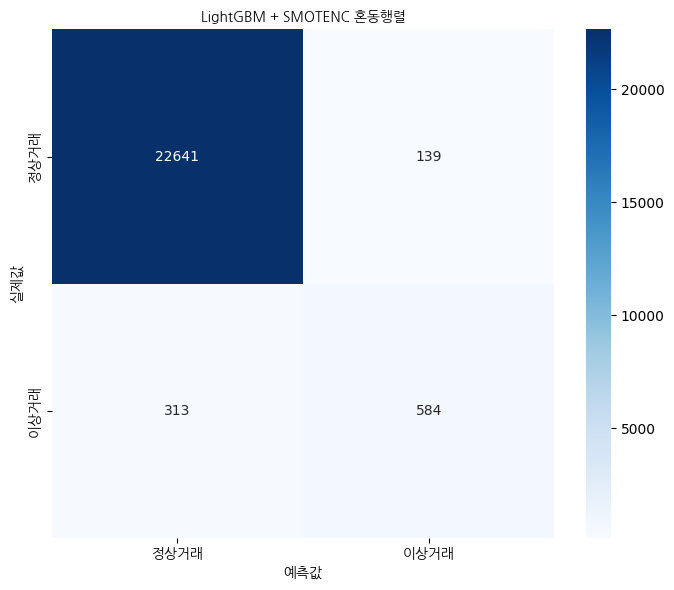

In [19]:
# @title
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


# 한글 폰트 경로를 지정합니다.
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_prop = fm.FontProperties(fname=font_path)


# 혼동행렬을 계산합니다.
lgb_cm = confusion_matrix(
    y_test,
    test_pred,
)


# 혼동행렬을 출력합니다.
print("LightGBM 혼동행렬")
print(lgb_cm)


# 혼동행렬을 그립니다.
plt.figure(figsize=(7, 6))

ax = sns.heatmap(
    lgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["정상거래", "이상거래"],
    yticklabels=["정상거래", "이상거래"],
)


# 한글 폰트를 각 요소에 직접 적용합니다.
ax.set_xticklabels(
    ["정상거래", "이상거래"],
    fontproperties=font_prop,
)

ax.set_yticklabels(
    ["정상거래", "이상거래"],
    fontproperties=font_prop,
)

plt.xlabel(
    "예측값",
    fontproperties=font_prop,
)

plt.ylabel(
    "실제값",
    fontproperties=font_prop,
)

plt.title(
    "LightGBM + SMOTENC 혼동행렬",
    fontproperties=font_prop,
)

plt.tight_layout()
plt.show()

## 혼동행렬 위치별 의미

혼동행렬은 행이 실제 거래 유형이고, 열이 모델의 예측 결과이다.

| 위치 | 의미 |
|---|---|
| 왼쪽 위 | 실제 정상거래를 정상거래로 정확히 예측한 경우 |
| 오른쪽 위 | 실제 정상거래를 이상거래로 잘못 예측한 경우이며, **오탐**이다 |
| 왼쪽 아래 | 실제 이상거래를 정상거래로 잘못 예측한 경우이며, **미탐**이다 |
| 오른쪽 아래 | 실제 이상거래를 이상거래로 정확히 예측한 경우 |

현재 혼동행렬은 다음과 같다.

| 실제값＼예측값 | 정상거래 | 이상거래 |
|---|---:|---:|
| 정상거래 | 22,641 | 139 |
| 이상거래 | 313 | 584 |

### 결과 해석

- 왼쪽 위 `22,641건`
  - 정상거래를 정상거래로 정확하게 분류했다.
  - 정상거래를 잘 구분한 결과이다.

- 오른쪽 위 `139건`
  - 정상거래인데 이상거래라고 판단했다.
  - 실제 고객에게 불필요한 경고를 보낸 경우이다.
  - 이런 오류를 **오탐**이라고 한다.

- 왼쪽 아래 `313건`
  - 실제 이상거래인데 정상거래로 판단했다.
  - 이상거래를 놓친 경우이다.
  - 이런 오류를 **미탐**이라고 한다.
  - 이상거래 탐지에서는 특히 주의해야 하는 오류이다.

- 오른쪽 아래 `584건`
  - 이상거래를 이상거래로 정확하게 탐지했다.
  - 모델이 이상거래를 제대로 찾아낸 결과이다.

### 전체적인 의미

실제 이상거래는 총 `897건`이며, 이 중 `584건`을 찾아냈다.  
따라서 실제 이상거래의 약 65%를 탐지하고, `313건`은 놓쳤다.

정상거래는 총 `22,780건`이며, 이 중 `22,641건`을 정상거래로 정확하게 분류했다.  
정상거래를 이상거래로 잘못 판단한 경우는 `139건`으로 비교적 적었다.

즉, 현재 모델은 정상거래를 정확하게 구분하는 데 강점이 있다.  
하지만 이상거래의 일부를 놓치는 미탐이 발생하므로, 이상거래를 더 많이 탐지하려면 임계값을 낮추는 방법을 고려할 수 있다.

다만 임계값을 낮추면 오탐도 증가할 수 있으므로, 이상거래 미탐과 정상거래 오탐 사이의 균형을 고려해야 한다.

## LightGBM 변수 중요도 분석

최종 모델인 LightGBM이 이상거래를 탐지할 때 어떤 변수를 중요하게 사용했는지 확인한다.

변수 중요도는 모델이 학습 과정에서 각 변수를 얼마나 많이 활용했는지를 나타내며, 값이 클수록 모델의 예측에 더 큰 영향을 준 변수로 해석할 수 있다.

,feature,importance
0,amt,600697.462590
1,hour,75164.720705
2,limit,32107.509036
3,days_since_last,25833.669644
4,amt_to_limit_ratio,23305.458315
5,amt_diff_from_user_avg,18864.348975
6,is_new_merchant,2635.993377
7,is_online,2009.298965
8,is_weekend,817.369234
9,is_overseas,37.813490


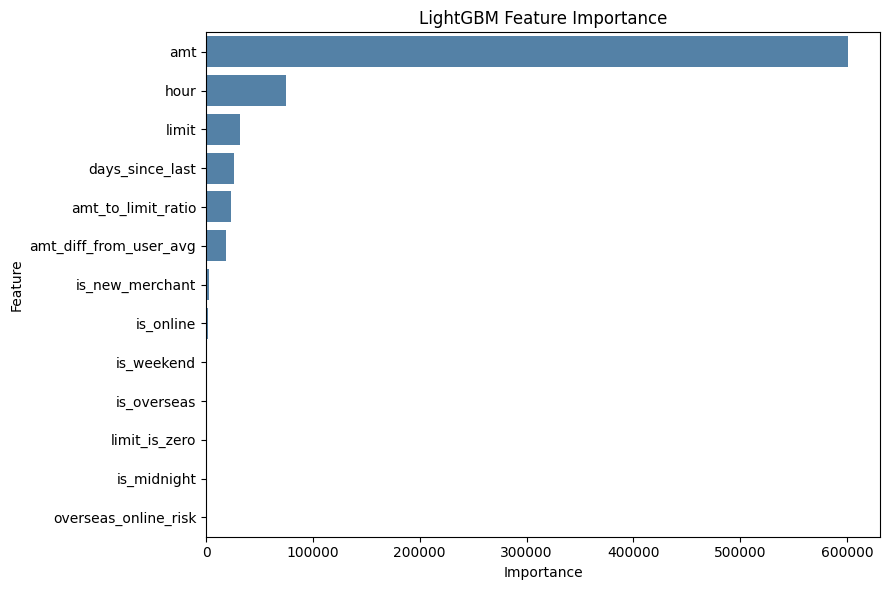

In [20]:
# @title
# 변수 중요도를 데이터프레임으로 정리합니다.
importance_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": lgb_model.booster_.feature_importance(
        importance_type="gain"
    ),
})


# 중요도가 높은 순서로 정렬합니다.
importance_df = importance_df.sort_values(
    "importance",
    ascending=False,
).reset_index(drop=True)


# 변수 중요도 표를 출력합니다.
display(importance_df)


# 변수 중요도를 시각화합니다.
plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    color="steelblue",
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## LightGBM 변수 중요도 해석

변수 중요도는 LightGBM 모델이 이상거래를 분류할 때 각 변수를 얼마나 많이 활용했는지를 나타낸다.

### 주요 결과

- `amt`
  - 승인금액의 중요도가 가장 높다.
  - 현재 모델은 거래금액을 이상거래 판단에 가장 많이 활용하고 있다.

- `hour`
  - 거래시간이 두 번째로 중요하다.
  - 특정 시간대에 발생한 거래가 이상거래 판단에 영향을 주는 것으로 나타났다.

- `limit`
  - 카드 이용한도도 이상거래 판단에 영향을 주는 변수이다.

- `days_since_last`
  - 최근 이용 이후 경과일수가 중요하게 사용되었다.
  - 평소 거래 간격과 다른 거래를 판단하는 데 도움이 될 수 있다.

- `amt_to_limit_ratio`
  - 승인금액이 카드 한도에서 차지하는 비율도 일부 영향을 주었다.

- `amt_diff_from_user_avg`
  - 현재 승인금액과 카드별 평균 결제금액의 차이도 이상거래 탐지에 활용되었다.
  - 평소보다 금액이 크게 달라진 거래를 판단하는 데 도움이 될 수 있다.

### 중요도가 낮은 변수

`is_new_merchant`, `is_online`, `is_weekend`, `is_overseas`, `limit_is_zero`, `is_midnight`, `overseas_online_risk`는 상대적으로 중요도가 낮게 나타났다.

이는 해당 변수들이 전혀 필요하지 않다는 뜻은 아니다. 다른 변수들과 함께 사용되면서 일부 거래의 판단에 도움을 줄 수 있지만, 현재 모델에서는 승인금액이나 거래시간보다 영향력이 작았다는 의미이다.

### 종합 해석

현재 모델은 승인금액, 거래시간, 카드한도, 최근 이용 경과일수와 같은 거래 규모와 거래 시점 관련 변수를 중심으로 이상거래를 판단하고 있다.

특히 `amt`의 중요도가 다른 변수보다 매우 높으므로, 승인금액이 이상거래 탐지에 가장 큰 영향을 준 것으로 해석할 수 있다.

단, 변수 중요도는 변수와 이상거래 사이의 인과관계를 의미하지 않는다. 또한 서로 비슷한 정보를 가진 변수끼리는 중요도가 나누어질 수 있으므로, 중요도가 낮다고 해서 해당 변수가 반드시 불필요한 것은 아니다.

## Soft Voting 확률 평균 앙상블

LightGBM, Random Forest, XGBoost가 예측한 이상거래 확률을 평균내어 최종 확률을 계산한다.

평균 확률이 임계값 `0.5` 이상이면 이상거래로 분류하고, `0.5` 미만이면 정상거래로 분류한다.

각 모델의 최종 예측값만 사용하는 다수결 방식과 달리, 모델이 예측한 확률을 함께 사용한다는 점이 특징이다. 이를 통해 여러 모델의 판단을 종합하여 단일 모델보다 안정적인 예측을 기대할 수 있다.

In [21]:
# @title
# 세 모델의 Validation 확률을 평균냅니다.
ensemble_valid_prob = (
    valid_prob
    + rf_valid_prob
    + xgb_valid_prob
) / 3


# 세 모델의 Test 확률을 평균냅니다.
ensemble_test_prob = (
    test_prob
    + rf_test_prob
    + xgb_test_prob
) / 3


# 임계값 0.5를 적용합니다.
ensemble_valid_pred = (
    ensemble_valid_prob >= 0.5
).astype(int)

ensemble_test_pred = (
    ensemble_test_prob >= 0.5
).astype(int)


# Validation 결과를 출력합니다.
print("[Soft Voting Validation 결과]")
print(classification_report(
    y_valid,
    ensemble_valid_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            ensemble_valid_prob,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[Soft Voting Test 결과]")
print(classification_report(
    y_test,
    ensemble_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            ensemble_test_prob,
        ),
        4,
    ),
)

[Soft Voting Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9873    0.9952    0.9912     11391
        이상거래     0.8459    0.6741    0.7503       448

    accuracy                         0.9830     11839
   macro avg     0.9166    0.8346    0.8708     11839
weighted avg     0.9819    0.9830    0.9821     11839

Validation PR-AUC: 0.7773

[Soft Voting Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9866    0.9937    0.9902     22780
        이상거래     0.8049    0.6577    0.7239       897

    accuracy                         0.9810     23677
   macro avg     0.8958    0.8257    0.8570     23677
weighted avg     0.9797    0.9810    0.9801     23677

Test PR-AUC: 0.7642


In [22]:
# @title
# LightGBM + XGBoost 확률 평균
lgb_xgb_valid_prob = (
    valid_prob
    + xgb_valid_prob
) / 2

lgb_xgb_test_prob = (
    test_prob
    + xgb_test_prob
) / 2


# LightGBM + Random Forest 확률 평균
lgb_rf_valid_prob = (
    valid_prob
    + rf_valid_prob
) / 2

lgb_rf_test_prob = (
    test_prob
    + rf_test_prob
) / 2


# 임계값 0.5 적용
lgb_xgb_valid_pred = (
    lgb_xgb_valid_prob >= 0.5
).astype(int)

lgb_xgb_test_pred = (
    lgb_xgb_test_prob >= 0.5
).astype(int)

lgb_rf_valid_pred = (
    lgb_rf_valid_prob >= 0.5
).astype(int)

lgb_rf_test_pred = (
    lgb_rf_test_prob >= 0.5
).astype(int)


# LightGBM + XGBoost 결과
print("[LightGBM + XGBoost Test 결과]")
print(classification_report(
    y_test,
    lgb_xgb_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            lgb_xgb_test_prob,
        ),
        4,
    ),
)


# LightGBM + Random Forest 결과
print("\n[LightGBM + Random Forest Test 결과]")
print(classification_report(
    y_test,
    lgb_rf_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            lgb_rf_test_prob,
        ),
        4,
    ),
)

[LightGBM + XGBoost Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9864    0.9945    0.9904     22780
        이상거래     0.8228    0.6522    0.7276       897

    accuracy                         0.9815     23677
   macro avg     0.9046    0.8233    0.8590     23677
weighted avg     0.9802    0.9815    0.9805     23677

Test PR-AUC: 0.7659

[LightGBM + Random Forest Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9869    0.9934    0.9901     22780
        이상거래     0.7989    0.6644    0.7255       897

    accuracy                         0.9810     23677
   macro avg     0.8929    0.8289    0.8578     23677
weighted avg     0.9798    0.9810    0.9801     23677

Test PR-AUC: 0.7633


## 이중 모델 앙상블 성능 비교

LightGBM과 XGBoost, LightGBM과 Random Forest의 이상거래 확률을 각각 평균내어 Test 성능을 비교하였다. 두 앙상블 모두 임계값 0.5를 사용하였다.

### Test 결과 비교

| 모델 | Precision | Recall | F1-score | PR-AUC | Accuracy |
|---|---:|---:|---:|---:|---:|
| LightGBM + XGBoost | **0.8228** | 0.6522 | **0.7276** | **0.7659** | **0.9815** |
| LightGBM + Random Forest | 0.7989 | **0.6644** | 0.7255 | 0.7633 | 0.9810 |

### LightGBM + XGBoost 해석

LightGBM과 XGBoost 앙상블은 이상거래 Precision `0.8228`, Recall `0.6522`, F1-score `0.7276`, PR-AUC `0.7659`를 기록하였다.

세 모델 평균 앙상블의 F1-score `0.7239`보다 높고, 단일 XGBoost의 F1-score `0.7248`보다도 높았다. 또한 PR-AUC가 `0.7659`로 전체 모델 중 가장 높게 나타났다.

### LightGBM + Random Forest 해석

LightGBM과 Random Forest 앙상블은 Recall이 `0.6644`로 두 앙상블 중 가장 높았다.

따라서 실제 이상거래를 더 많이 탐지할 수 있다는 장점이 있다. 그러나 Precision은 `0.7989`로 LightGBM + XGBoost보다 낮아 정상거래를 이상거래로 잘못 판단하는 오탐이 더 많이 발생하였다.

### 종합 결론

LightGBM + XGBoost 앙상블은 F1-score, PR-AUC, Precision, Accuracy에서 더 높은 성능을 보였다.

LightGBM + Random Forest 앙상블은 Recall이 더 높아 이상거래를 놓치지 않는 것이 중요한 경우에 적합하다.

전체적인 성능과 Precision, F1-score, PR-AUC를 종합하면 **LightGBM + XGBoost 앙상블을 최종 앙상블 후보로 선택하는 것이 적절하다.**

## SMOTENC 비율별 LightGBM 성능 비교

SMOTENC의 `sampling_strategy`를 변경하여 이상거래 데이터 증강 비율에 따른 LightGBM 성능 변화를 비교한다.

각 비율의 성능은 Validation 데이터로 비교하고, 가장 높은 F1-score를 보인 비율을 선택하여 Test 데이터에서 최종 평가한다.

In [23]:
# @title
# SMOTENC를 가져옵니다.
from imblearn.over_sampling import SMOTENC

# LightGBM을 가져옵니다.
from lightgbm import LGBMClassifier

# 평가 지표를 가져옵니다.
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

# 결과 저장용 리스트를 만듭니다.
results = []

# SMOTENC 비율을 하나씩 실험합니다.
for ratio in [0.1, 0.2, 0.3, 0.5]:

    # 현재 비율로 SMOTENC를 생성합니다.
    smote = SMOTENC(
        categorical_features=categorical_indices,
        sampling_strategy=ratio,
        random_state=42,
    )

    # Train 데이터에만 SMOTENC를 적용합니다.
    X_res, y_res = smote.fit_resample(
        X_train_scaled,
        y_train,
    )

    # LightGBM 모델을 생성합니다.
    model = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    )

    # SMOTENC가 적용된 Train 데이터로 학습합니다.
    model.fit(X_res, y_res)

    # Validation 이상거래 확률을 예측합니다.
    prob = model.predict_proba(
        X_valid_scaled
    )[:, 1]

    # 임계값 0.5로 최종 분류합니다.
    pred = (prob >= 0.5).astype(int)

    # 현재 비율의 성능을 저장합니다.
    results.append({
        "SMOTENC 비율": ratio,
        "Precision": precision_score(
            y_valid,
            pred,
        ),
        "Recall": recall_score(
            y_valid,
            pred,
        ),
        "F1-score": f1_score(
            y_valid,
            pred,
        ),
        "PR-AUC": average_precision_score(
            y_valid,
            prob,
        ),
    })

# 실험 결과를 표로 변환합니다.
ratio_table = pd.DataFrame(results)

# F1-score가 높은 순서로 정렬합니다.
ratio_table = ratio_table.sort_values(
    "F1-score",
    ascending=False,
)

# 비율별 성능을 출력합니다.
display(ratio_table)

# 가장 좋은 SMOTENC 비율을 출력합니다.
print(
    "최적 비율:",
    ratio_table.iloc[0]["SMOTENC 비율"],
)

,SMOTENC 비율,Precision,Recall,F1-score,PR-AUC
1,0.2,0.853448,0.662946,0.746231,0.781754
2,0.3,0.837989,0.669643,0.744417,0.782553
0,0.1,0.843931,0.651786,0.735516,0.779662
3,0.5,0.814208,0.665179,0.732187,0.768207


최적 비율: 0.2


## 20. 금융 이상거래 3단계 경보 시연

기존 **LightGBM `test_prob`** 예측 결과를 그대로 사용합니다.

- 녹색: 예측 확률 30% 미만 / 노랑: 30~50% 미만 / 적색: 50% 이상
- 임계값은 시연용 기준이며 실제 결제 차단은 구현하지 않았습니다.
- 음성은 `gTTS`를 이용하므로 생성 시 인터넷 접속이 필요합니다. 재생은 오디오 플레이어의 ▶ 버튼을 누릅니다.
- 학습 때 저장한 모델과 `test_prob`, `test_df`가 이미 준비되어 있어야 합니다.

In [4]:
# 처음 한 번만 실행: 음성을 만들기 위한 도구 설치
!pip -q install gTTS pydub

In [2]:
# 1. 사용할 라이브러리
import numpy as np
import pandas as pd
from html import escape
from io import BytesIO
from IPython.display import display, HTML, Audio
from gtts import gTTS
from pydub import AudioSegment
from pydub.generators import Sine

# 2. 경보를 나누는 기준 (시연용)
CAUTION = 0.30
BLOCK = 0.50

# 3. 앞에서 계산한 LightGBM 예측 확률을 가져오기
if "test_prob" not in globals() or "test_df" not in globals():
    raise RuntimeError("먼저 LightGBM Test 예측 셀을 실행하세요.")

prob = np.asarray(test_prob, dtype=float)
if len(prob) != len(test_df):
    raise ValueError("예측 확률과 Test 데이터 행 수가 다릅니다.")

# 4. 확률 구간별 거래 위치 찾기
valid = np.isfinite(prob) & (prob >= 0) & (prob <= 1)
green_rows = np.where(valid & (prob < CAUTION))[0]
yellow_rows = np.where(valid & (prob >= CAUTION) & (prob < BLOCK))[0]
red_rows = np.where(valid & (prob >= BLOCK))[0]

# 5. 단계별 화면 색상, 메시지, 음성 안내
# 각 단계별로: 제목, 글자색, 배경색, 안내문, 음성문, 경고음 횟수, 음높이
# 5. 단계별 화면 색상 및 음성 안내
# 제목, 글자색, 배경색, 음성문, 경고음 횟수, 음높이
ALERTS = {
    "green": (
        "정상거래", "#116329", "#EDF8EF",
        "안내합니다. 정상 거래로 예측되었습니다. 거래 내역을 확인해 주세요.",
        1, 540
    ),
    "yellow": (
        "이상거래 의심", "#995100", "#FFF2DB",
        "주의하세요. 이상 거래가 의심됩니다. 본인이 결제한 거래인지 확인해 주세요.",
        2, 750
    ),
    "red": (
        "위험거래 차단", "#9F1D1D", "#FFF0F0",
        "긴급 경고입니다. 높은 위험의 이상 거래가 예측되었습니다. "
        "차단 경보 시연이며 실제 거래는 차단되지 않았습니다. 카드사에 문의해 주세요.",
        3, 980
    )
}


# 6. 선택한 단계의 시각·청각 경보 표시
def show_alert(level):

    # 해당 경보 단계의 Test 거래 위치 가져오기
    rows = {
        "green": green_rows,
        "yellow": yellow_rows,
        "red": red_rows
    }[level]

    # 해당 단계에 거래가 없는 경우
    if len(rows) == 0:
        print("이 단계에 해당하는 Test 거래가 없습니다:", level)
        return

    # 정상거래는 21번과 동일한 기준으로 선택
    if level == "green":

        # 0번을 제외하고 예측 확률 0.1%~10%인 거래 찾기
        candidates = rows[
            (rows != 0) &
            (prob[rows] >= 0.001) &
            (prob[rows] < 0.10)
        ]

        if len(candidates) > 0:

            # 3%에 가장 가까운 실제 정상거래 선택
            i = int(candidates[
                np.argmin(np.abs(prob[candidates] - 0.03))
            ])

        else:

            # 조건에 맞는 거래가 없으면 다른 정상거래 선택
            candidates = rows[rows != 0]

            if len(candidates) == 0:
                print("0번을 제외한 정상거래가 없습니다.")
                return

            i = int(candidates[np.argmax(prob[candidates])])

    else:
        # 노란색과 적색 단계는 첫 번째 거래 선택
        i = int(rows[0])

    # 선택한 실제 Test 거래 가져오기
    row = test_df.iloc[i]
    risk = prob[i]


    # 경보 단계별 설정 불러오기
    title, color, bg, voice, repeat, hz = ALERTS[level]

    # 결제 금액 가져오기
    amount = pd.to_numeric(
        row.get("통합승인금액"),
        errors="coerce"
    )

    amount_text = (
        f"{amount:,.0f}원"
        if pd.notna(amount)
        else "정보 없음"
    )

    # 거래 날짜 가져오기
    date_value = pd.to_datetime(
        str(row.get("승인일자")),
        format="%Y%m%d",
        errors="coerce"
    )

    # 거래 시간 가져오기
    hour_value = pd.to_numeric(
        row.get("승인시간대"),
        errors="coerce"
    )

    # 거래일시 형식 변경
    if pd.notna(date_value) and pd.notna(hour_value):
        date_text = date_value.strftime("%Y년 %m월 %d일")
        hour_text = f"{int(hour_value):02d}시"
        datetime_text = f"{date_text} {hour_text}"
    else:
        datetime_text = "정보 없음"

    # (1) 큰 글씨 경보 카드 표시
    display(HTML(f"""
    <div style="
        width:1200px;
        max-width:none;
        box-sizing:border-box;
        border:7px solid {color};
        background:{bg};
        border-radius:22px;
        padding:45px;
        font-family:Arial,sans-serif;
        line-height:1.5;
        color:#171717;
    ">

        <!-- 경보 제목 -->
        <div style="
            font-size:56px;
            font-weight:900;
            color:{color};
        ">
            {title}
        </div>


        <!-- 이상거래 예측 확률 -->
        <div style="
            font-size:30px;
            margin-top:25px;
        ">
            이상거래 확률
        </div>

        <div style="
            font-size:64px;
            font-weight:900;
            color:{color};
        ">
            {risk:.1%}
        </div>

        <!-- 위험 확률 막대 -->
        <div style="
            background:#dddddd;
            height:30px;
            border-radius:12px;
            overflow:hidden;
            margin-top:10px;
        ">
            <div style="
                background:{color};
                width:{risk*100:.1f}%;
                height:30px;
            "></div>
        </div>

        <!-- 결제 금액: 글자 크게 -->
        <div style="
            font-size:50px;
            font-weight:900;
            margin-top:30px;
        ">
            결제 금액: {escape(amount_text)}
        </div>

        <!-- 거래일시 -->
        <div style="
            font-size:28px;
            font-weight:600;
            margin-top:10px;
        ">
            거래일시 : {escape(datetime_text)}
        </div>

        <!-- 음성 안내: 오른쪽 정렬 -->
        <div style="
            font-size:27px;
            font-weight:bold;
            margin-top:35px;
            text-align:right;
            line-height:1.6;
        ">
            ▶ 음성 안내를 들으시려면 아래 재생 버튼을 눌러주십시오.
        </div>

    </div>
    """))

    # (2) 한국어 안내 음성 생성
    voice_file = BytesIO()

    gTTS(
        text=voice,
        lang="ko"
    ).write_to_fp(voice_file)

    voice_file.seek(0)

    spoken = AudioSegment.from_file(
        voice_file,
        format="mp3"
    )

    # (3) 단계별 경고음 생성
    alarm = AudioSegment.silent(duration=150)

    for _ in range(repeat):
        alarm += Sine(hz).to_audio_segment(
            duration=230
        ).apply_gain(-12)

        alarm += AudioSegment.silent(
            duration=160
        )

    # 경고음과 한국어 음성 합치기
    combined = alarm + spoken

    # (4) 오디오 재생기 출력
    output = BytesIO()

    combined.export(
        output,
        format="wav"
    )

    display(
        Audio(
            data=output.getvalue(),
            autoplay=False
        )
    )

    print(
        f"선택된 Test 위치: {i} / "
        f"이상거래 예측 확률: {risk:.1%}"
    )


print("경보 시연 준비 완료")
print("정상거래:", len(green_rows), "건")
print("이상거래 의심:", len(yellow_rows), "건")
print("차단 대상 경보:", len(red_rows), "건")

ModuleNotFoundError: No module named 'gtts'

In [50]:
# 정상거래
show_alert("green")

선택된 Test 위치: 8447 / 이상거래 예측 확률: 3.0%


In [28]:
# 이상거래 의심
show_alert("yellow")

선택된 Test 위치: 23 / 이상거래 예측 확률: 64.0%


In [29]:
# 위험거래 차단
show_alert("red")

선택된 Test 위치: 14 / 이상거래 예측 확률: 93.3%


### 발표 때 설명하기

1. `test_prob`는 LightGBM이 예측한 이상거래 클래스(1)의 확률 추정값입니다. 실제 사기 확률로 단정하지 않습니다.
2. `np.where()`로 확률에 따라 정상·의심·차단 대상 구간의 **Test 거래 위치**를 찾습니다.
3. `test_df.iloc[i]`로 같은 위치의 거래 날짜·금액을 가져옵니다.
4. HTML 출력으로 어르신이 읽기 쉬운 큰 글씨, 배경색, 예측 확률 막대를 표시합니다.
5. `gTTS`로 한국어 음성을 만들고, `pydub`로 1~3회 경고음을 음성 앞에 붙입니다.
6. Colab 오디오 플레이어의 ▶ 버튼을 클릭하여 재생합니다. 별도 UI/실시간 카드 차단 시스템은 아닙니다.

주의: gTTS는 인터넷 연결이 필요합니다. 오디오 파일 생성이 느릴 수 있으므로 영상 촬영 전에 셀을 한 번 실행해 출력을 준비하는 것이 좋습니다.

## 21. FastAPI + Streamlit + Web Speech API + 응답시간 측정


실행 전 : LightGBM 학습·평가 셀까지 실행하여 `lgb_model`, `X_test_scaled`, `test_prob`, `test_df`가 있어야 합니다.


실행 순서 : **21-1 설치 → 21-2 데이터 저장 → 21-3 FastAPI 생성 → 21-4 API 서버 시작 → 21-5 API 시간 측정 → 21-6 Streamlit 생성 → 21-7 앱 실행**

- **FastAPI**: 전처리된 거래 데이터를 받아 LightGBM으로 이상거래 확률을 예측합니다 (`/predict`, `/predict_batch`).
- **Streamlit**: FastAPI에 요청하여 대형 경보 **팝업**을 표시합니다.
- **Web Speech API**: 팝업 내부 버튼 클릭 시 한국어 음성을 읽습니다.
- **100ms**: 측정 목표로만 취급합니다. 아래에서 실제 응답시간을 측정하고 **평균·P95**를 출력합니다. 목표 미달이면 그대로 보고합니다.

예시는 **Colab에서 이미 전처리된 값**을 전달합니다. 실제 원본 카드 거래를 받아 자동 전처리하는 서비스나 카드 승인 차단 시스템은 아닙니다.

In [30]:
# 21-1. 필요한 웹 서비스 라이브러리 설치 (Colab에서 최초 1회)
%pip -q install fastapi uvicorn streamlit requests joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 66.7 MB/s eta 0:00:00


### 21-2. 기존 LightGBM 모델과 실제 Test 시연용 거래 저장

전처리된 입력 피처와 화면에 표시할 금액·날짜는 구분해서 저장합니다. 실제 Test 예측 확률이 30% 미만, 30~70% 미만, 70% 이상인 거래 중 각각 첫 번째 거래를 선택합니다. 없는 단계는 임의 확률로 만들지 않습니다.

In [41]:
import json
import joblib
import numpy as np
import pandas as pd

# 1. 모델 학습 및 예측 결과 확인
for name in ["lgb_model", "X_test_scaled", "test_prob", "test_df"]:
    if name not in globals():
        raise RuntimeError(f"{name} 변수가 없습니다. 먼저 LightGBM 학습 및 Test 예측 셀을 실행하세요.")

# 2. 학습 완료 모델 저장
joblib.dump(lgb_model, "fds_lgb_model.joblib")

feature_names = X_test_scaled.columns.tolist()

with open("fds_feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_names, f, ensure_ascii=False)

# 3. 실제 Test 예측 확률 가져오기
probabilities = np.asarray(test_prob, dtype=float).reshape(-1)

if len(probabilities) != len(X_test_scaled) or len(probabilities) != len(test_df):
    raise ValueError("Test 행 개수가 일치하지 않습니다.")

# 4. 이상거래 예측 확률에 따라 3단계 구분
valid = np.isfinite(probabilities) & (probabilities >= 0) & (probabilities <= 1)

groups = {
    "정상거래": np.where(valid & (probabilities < 0.30))[0],
    "이상거래 의심": np.where(valid & (probabilities >= 0.30) & (probabilities < 0.50))[0],
    "의심거래 차단 대상": np.where(valid & (probabilities >= 0.50))[0],
}

# 5. 각 단계별 시연 거래 선택
examples = []

for stage, indices in groups.items():

    if len(indices) == 0:
        print(f"주의: {stage} 구간에는 실제 Test 거래가 없습니다.")
        continue

    # 정상거래: 0번을 제외하고 3%에 가까운 거래 선택
    if stage == "정상거래":

        candidates = indices[
            (indices != 0) &
            (probabilities[indices] >= 0.001) &
            (probabilities[indices] < 0.10)
        ]

        if len(candidates) > 0:
            i = int(candidates[
                np.argmin(np.abs(probabilities[candidates] - 0.03))
            ])
        else:
            # 0.1%~10% 거래가 없으면 다른 정상거래 선택
            candidates = indices[indices != 0]

            if len(candidates) == 0:
                print("0번을 제외한 정상거래가 없습니다.")
                continue

            i = int(candidates[np.argmax(probabilities[candidates])])

    # 이상거래 의심 및 차단 대상은 기존 방식 유지
    else:
        i = int(indices[0])

    # 6. 선택한 거래 정보 가져오기
    row = test_df.iloc[i]

    values = X_test_scaled.iloc[i].astype(float).to_numpy()

    if not np.isfinite(values).all():
        print(f"주의: {stage} 시연 데이터에 유효하지 않은 값이 있어 건너뜁니다.")
        continue

    # 가맹점 컬럼 확인
    merchant_col = next(
        (c for c in ["가맹점명", "가맹점상호", "가맹점업종명"]
         if c in test_df.columns),
        None
    )

    # 결제 금액
    amount = pd.to_numeric(
        row.get("통합승인금액"),
        errors="coerce"
    )

    # 거래 날짜와 시간
    date_value = pd.to_datetime(
        str(row.get("승인일자")),
        format="%Y%m%d",
        errors="coerce"
    )

    hour_value = pd.to_numeric(
        row.get("승인시간대"),
        errors="coerce"
    )

    if pd.notna(date_value) and pd.notna(hour_value):
        datetime_text = (
            f"{date_value.strftime('%Y년 %m월 %d일')} "
            f"{int(hour_value):02d}시"
        )
    else:
        datetime_text = "정보 없음"

    # 7. 시연용 거래 목록에 추가
    examples.append({
        "stage": stage,
        "row_index": i,
        "features": values.tolist(),
        "amount": f"{amount:,.0f}원" if pd.notna(amount) else "정보 없음",
        "date": str(row.get("승인일자", "정보 없음")),
        "datetime": datetime_text,
        "merchant": str(row[merchant_col]) if merchant_col else "정보 없음",
    })

# 8. 시연용 거래 저장
if not examples:
    raise RuntimeError("시연에 사용할 유효한 Test 거래가 없습니다.")

with open("fds_demo_examples.json", "w", encoding="utf-8") as f:
    json.dump(examples, f, ensure_ascii=False, indent=2)

# 9. 저장 결과 확인
print("모델 및 예시 거래 저장 완료")

for example in examples:
    i = example["row_index"]

    print(
        f"{example['stage']}: "
        f"Test 위치 {i}, "
        f"예측 확률 {probabilities[i]:.2%}"
    )

print("파일: fds_lgb_model.joblib / fds_feature_names.json / fds_demo_examples.json")

모델 및 예시 거래 저장 완료
정상거래: Test 위치 8447, 예측 확률 3.00%
이상거래 의심: Test 위치 23, 예측 확률 64.00%
의심거래 차단 대상: Test 위치 14, 예측 확률 93.33%
파일: fds_lgb_model.joblib / fds_feature_names.json / fds_demo_examples.json


### 21-3. FastAPI 코드 파일 작성

`/predict`는 한 건, `/predict_batch`는 여러 건을 한번에 예측합니다. 서버는 모델을 시작할 때 **한 번만 로드**합니다.

In [42]:
%%writefile fds_api.py
"""Card-FDS-N: LightGBM 모델로 1건·배치 이상거래 예측을 제공하는 FastAPI.

실행: uvicorn fds_api:app --host 127.0.0.1 --port 8000
주의: 입력 features는 Colab에서 학습에 사용한 순서대로 전처리된 값입니다.
"""
import json
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

HERE = Path(__file__).resolve().parent
model = joblib.load(HERE / "fds_lgb_model.joblib")
feature_names = json.loads((HERE / "fds_feature_names.json").read_text(encoding="utf-8"))

app = FastAPI(title="Card-FDS-N 이상거래 예측 API")


class OneTransaction(BaseModel):
    features: list[float]


class MultipleTransactions(BaseModel):
    rows: list[list[float]]


def validate_rows(rows):
    # 입력 피처 개수와 숫자 범위를 점검합니다.
    if not rows or len(rows) > 1000:
        raise HTTPException(400, "1~1000건만 요청할 수 있습니다.")
    if any(len(row) != len(feature_names) for row in rows):
        raise HTTPException(400, "피처 개수가 학습 모델과 다릅니다.")
    values = np.asarray(rows, dtype=float)
    if not np.isfinite(values).all():
        raise HTTPException(400, "유효하지 않은 숫자가 포함되었습니다.")
    return pd.DataFrame(values, columns=feature_names)


def level_name(prob):
    if prob < 0.30:
        return "정상거래"
    if prob < 0.70:
        return "이상거래 의심"
    return "의심거래 차단 대상 (시연)"


@app.get("/health")
def health():
    return {"status": "ok", "model": "LightGBM"}


@app.post("/predict")
def predict(item: OneTransaction):
    X = validate_rows([item.features])
    start = perf_counter()
    p = float(model.predict_proba(X)[0, 1])
    model_ms = (perf_counter() - start) * 1000
    return {
        "fraud_probability": p,
        "alert_level": level_name(p),
        "model_inference_ms": round(model_ms, 3),
        "notice": "경보 시연이며 실제 카드 결제를 차단하지 않습니다.",
    }


@app.post("/predict_batch")
def predict_batch(item: MultipleTransactions):
    X = validate_rows(item.rows)
    start = perf_counter()
    probabilities = model.predict_proba(X)[:, 1]
    model_ms = (perf_counter() - start) * 1000
    return {
        "count": len(probabilities),
        "fraud_probabilities": probabilities.astype(float).tolist(),
        "alert_levels": [level_name(float(p)) for p in probabilities],
        "model_inference_ms": round(model_ms, 3),
    }


Overwriting fds_api.py


### 21-4. Colab에서 FastAPI 서버 시작 및 통신 확인

`uvicorn`이라는 실행기로 API 서버를 켭니다. 이 셀은 서버를 백그라운드로 실행하므로 다음 셀도 실행할 수 있습니다. Colab 내부 주소 `127.0.0.1:8000`을 사용하며, 외부에 서비스를 배포하는 코드는 아닙니다.

In [43]:
import os
import sys
import time
import subprocess
import requests

# 셀 재실행 시 기존에 켰던 서버를 종료
if "fds_api_proc" in globals() and fds_api_proc.poll() is None:
    fds_api_proc.terminate()
    fds_api_proc.wait(timeout=10)

api_log = open("fds_api.log", "w", encoding="utf-8")
fds_api_proc = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "fds_api:app", "--host", "127.0.0.1", "--port", "8000"],
    stdout=api_log, stderr=subprocess.STDOUT, cwd=os.getcwd(),
)

# 서버가 실제로 켜질 때까지 기다림 (최대 약 20초)
for _ in range(40):
    if fds_api_proc.poll() is not None:
        raise RuntimeError("FastAPI 시작 실패. fds_api.log 파일을 확인하세요.")
    try:
        response = requests.get("http://127.0.0.1:8000/health", timeout=1)
        if response.ok:
            print("FastAPI 실행 성공:", response.json())
            break
    except requests.RequestException:
        pass
    time.sleep(0.5)
else:
    raise RuntimeError("FastAPI가 시작되지 않았습니다. fds_api.log 파일을 확인하세요.")

FastAPI 실행 성공: {'status': 'ok', 'model': 'LightGBM'}


### 21-5. 1건 API / 배치 API 응답시간 측정 (100ms 목표)

`perf_counter()`로 HTTP 요청 직전부터 응답을 받은 직후까지의 시간을 기록합니다. API 서버가 반환하는 `model_inference_ms`는 **모델 계산 시간만** 측정한 값으로 별개의 지표입니다.

- 측정 환경: Colab 런타임 내부(localhost) 통신입니다. 외부 인터넷을 통한 사용자 응답시간을 뜻하지 않습니다.
- `P95`: 측정값 중 약 95%가 그 이하인 시간입니다.

In [44]:
from time import perf_counter
import numpy as np
import pandas as pd
import requests

API_URL = "http://127.0.0.1:8000"
request_one = {"features": examples[0]["features"]}
request_batch = {"rows": X_test_scaled.iloc[:64].astype(float).values.tolist()}

# 예측이 노트북의 test_prob와 동일한지 확인
check = requests.post(API_URL + "/predict", json=request_one, timeout=20)
check.raise_for_status()
api_prob = float(check.json()["fraud_probability"])
expected_prob = float(probabilities[examples[0]["row_index"]])
print(f"노트북 예측: {expected_prob:.6f} / API 예측: {api_prob:.6f}")
assert np.isclose(api_prob, expected_prob, atol=1e-6), "API와 노트북 결과가 다릅니다."

# 첫 실행 준비 시간을 줄이도록 예열
for _ in range(3):
    requests.post(API_URL + "/predict", json=request_one, timeout=20).raise_for_status()

# 실제 HTTP 요청 전체 시간 측정
results = []
for name, endpoint, body, repeats in [
    ("1건 API", "/predict", request_one, 30),
    ("64건 배치 API", "/predict_batch", request_batch, 10),
]:
    times = []
    for _ in range(repeats):
        start = perf_counter()
        r = requests.post(API_URL + endpoint, json=body, timeout=20)
        r.raise_for_status()
        times.append((perf_counter() - start) * 1000)
    avg = float(np.mean(times))
    p95 = float(np.percentile(times, 95))
    results.append({
        "구분": name,
        "반복": repeats,
        "평균 응답(ms)": round(avg, 2),
        "P95 응답(ms)": round(p95, 2),
        "100ms 목표(P95)": "달성" if p95 < 100 else "미달성",
    })

display(pd.DataFrame(results))
print("※ 서버·클라이언트가 같은 Colab 런타임에 있는 HTTP 응답시간입니다.")

노트북 예측: 0.030044 / API 예측: 0.030044


,구분,반복,평균 응답(ms),P95 응답(ms),100ms 목표(P95)
0,1건 API,30,3.32,3.50,달성
1,64건 배치 API,10,5.26,7.31,달성


※ 서버·클라이언트가 같은 Colab 런타임에 있는 HTTP 응답시간입니다.


### 21-6. Streamlit 대형 팝업 + Web Speech API 코드 파일 작성

Streamlit 화면에서 거래를 선택해 **FastAPI `/predict`**를 호출합니다. 응답을 받아 **녹색·주황색·적색의 큰 경보 팝업**을 띄우며, 음성 버튼을 누르면 브라우저 **Web Speech API**가 한국어를 읽습니다. `st.markdown()` 내부의 `<script>` 실행에 의존하지 않도록 `components.html()`을 사용합니다.

In [45]:
%%writefile fds_streamlit.py
"""Card-FDS-N: + 브라우저 TTS."""
import json
import os
from html import escape
from pathlib import Path

import requests
import streamlit as st
import streamlit.components.v1 as components

HERE = Path(__file__).resolve().parent
API_URL = os.environ.get("FDS_API_URL", "http://127.0.0.1:8000")
examples = json.loads((HERE / "fds_demo_examples.json").read_text(encoding="utf-8"))

st.set_page_config(page_title="Card-FDS-N 금융거래 경보", layout="wide")
st.title("Card-FDS-N · 금융거래 알림")
st.caption("실제 Test 예측을 기반으로 한 시연이며 결제 승인·차단 기능은 없습니다.")


st.markdown("""
<style>
[data-testid="stDialog"] div[role="dialog"] {
    width: min(1260px, 96vw) !important;
    max-width: 96vw !important;
}
</style>
""", unsafe_allow_html=True)

if not examples:
    st.error("시연 가능한 거래가 없습니다. Colab에서 예측 결과를 먼저 저장하세요.")
    st.stop()

chosen = st.selectbox(
    "확인할 거래",
    range(len(examples)),
    format_func=lambda i: f"{examples[i]['stage']} · Test 위치 {examples[i]['row_index']}",
)


def alert_fraud_transaction(tx_info, risk_prob):

    if risk_prob < 0.30:
        title, color, bg = "정상거래", "#116329", "#EDF8EF"
        voice = "안내합니다. 정상 거래로 예측되었습니다. 거래 내역을 확인해 주세요."
    elif risk_prob < 0.70:
        title, color, bg = "이상거래 의심", "#995100", "#FFF2DB"
        voice = "주의하세요. 이상 거래가 의심됩니다. 본인이 결제한 거래인지 확인해 주세요."
    else:
        title, color, bg = "위험거래 차단", "#9F1D1D", "#FFF0F0"
        voice = (
            "긴급 경고입니다. 높은 위험의 이상 거래가 예측되었습니다. "
            "차단 경보 시연이며 실제 거래는 차단되지 않았습니다. 카드사에 문의해 주세요."
        )

    amount = escape(str(tx_info.get("amount", "정보 없음")))
    datetime_text = escape(str(tx_info.get("datetime", "정보 없음")))

    # (1) 큰 글씨 경보 카드 표시
    # st.html()을 사용하면 HTML 코드가 글자로 출력되는 문제를 방지할 수 있습니다.

    st.html(f"""
<div style="
    width:100%;
    box-sizing:border-box;
    border:7px solid {color};
    background:{bg};
    border-radius:22px;
    padding:45px;
    font-family:Arial,sans-serif;
    line-height:1.5;
    color:#171717;">

    <div style="font-size:56px;font-weight:900;color:{color};">
        {title}
    </div>

    <div style="font-size:30px;margin-top:25px;">
        이상거래 확률
    </div>

    <div style="font-size:64px;font-weight:900;color:{color};">
        {risk_prob:.2%}
    </div>

    <div style="background:#dddddd;height:30px;
                border-radius:12px;overflow:hidden;margin-top:10px;">
        <div style="background:{color};
                    width:{risk_prob*100:.1f}%;height:30px;"></div>
    </div>

    <div style="font-size:50px;font-weight:900;margin-top:30px;">
        결제 금액: {amount}
    </div>

    <div style="font-size:28px;font-weight:600;margin-top:10px;">
        거래일시 : {datetime_text}
    </div>

    <div style="font-size:27px;font-weight:bold;
                margin-top:35px;text-align:right;line-height:1.6;">
        ▶ 음성 안내를 들으시려면 아래 재생 버튼을 눌러주십시오.
    </div>

</div>
""")

    # 20번은 gTTS+경고음, 21번은 브라우저 Web Speech API로 음성을 읽습니다.
    voice_json = json.dumps(voice, ensure_ascii=False)
    components.html(f"""
    <div style="display:flex;justify-content:flex-end;align-items:center;">
      <button onclick="speakKorean()" style="font-size:27px;padding:16px 20px;
        background:{color};color:white;border:0;border-radius:12px;cursor:pointer;">
        🔊 한국어 음성 듣기
      </button>
    </div>
    <div id="speech-status" style="font-size:17px;margin-top:6px;text-align:right;"></div>
    <script>
    function speakKorean() {{
      if (!('speechSynthesis' in window)) {{
        document.getElementById('speech-status').textContent = '이 브라우저는 음성 안내를 지원하지 않습니다.';
        return;
      }}
      window.speechSynthesis.cancel();
      const speech = new SpeechSynthesisUtterance({voice_json});
      speech.lang = 'ko-KR';
      speech.rate = 0.85;
      speech.volume = 1;
      window.speechSynthesis.speak(speech);
    }}
    </script>
    """, height=105)


@st.dialog("카드 거래 경보", width="large")
def show_popup(result, selected):
    alert_fraud_transaction(
        tx_info=selected,
        risk_prob=float(result["fraud_probability"]),
    )
    st.caption(
        f"API 모델 추론시간: {result['model_inference_ms']:.3f}ms "
        "(전체 API 응답시간과 다름)"
    )


if st.button("선택한 거래 예측하고 경보 팝업 보기", type="primary", use_container_width=True):
    selected = examples[chosen]
    try:
        # 실제 LightGBM을 불러온 FastAPI에 예측 요청
        r = requests.post(
            API_URL + "/predict", json={"features": selected["features"]}, timeout=15
        )
        r.raise_for_status()
        result = r.json()
    except requests.RequestException as e:
        st.error(f"FastAPI 연결 실패: {e}")
    else:
        show_popup(result, selected)


Overwriting fds_streamlit.py


### 21-7. Streamlit 실행 후 팝업·음성 시연

Streamlit 앱을 Colab 내부에서 시작하고 브라우저 링크를 표시합니다. **Colab에서는 새 탭에 열리는 앱을 눌러** 3단계 경보와 TTS 버튼을 시연하세요. 링크 생성 기능은 Colab 환경·정책에 따라 달라질 수 있습니다.

- 실행 버튼: `선택한 거래 예측하고 경보 팝업 보기`
- 팝업 안의 버튼: `🔊 한국어 음성 듣기`
- 통합 확인: Streamlit이 **직접 예측하지 않고 FastAPI에 요청**합니다.
- 참고: Streamlit 앱 코드 안에는 `st.dialog` 팝업을 사용하므로 최근 Streamlit 버전이 필요합니다.

In [1]:
import os
import sys
import time
import subprocess
import requests

if "fds_streamlit_proc" in globals() and fds_streamlit_proc.poll() is None:
    fds_streamlit_proc.terminate()
    fds_streamlit_proc.wait(timeout=10)

ui_log = open("fds_streamlit.log", "w", encoding="utf-8")
fds_streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "fds_streamlit.py",
     "--server.address", "0.0.0.0", "--server.port", "8501", "--server.headless", "true",
     "--browser.gatherUsageStats", "false",

     # Colab 프록시 연결 문제를 확인하기 위한 임시 설정
    "--server.enableCORS", "false",
    "--server.enableXsrfProtection", "false",
     ],
    stdout=ui_log, stderr=subprocess.STDOUT, cwd=os.getcwd(),
)

for _ in range(40):
    if fds_streamlit_proc.poll() is not None:
        raise RuntimeError("Streamlit 시작 실패. fds_streamlit.log 파일을 확인하세요.")
    try:
        r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=1)
        if r.ok:
            break
    except requests.RequestException:
        pass
    time.sleep(0.5)
else:
    raise RuntimeError("Streamlit이 시작되지 않았습니다. fds_streamlit.log 파일을 확인하세요.")

print("Streamlit 실행 성공!")
try:
    from google.colab import output
    url = output.eval_js("google.colab.kernel.proxyPort(8501)")
    print("아래 주소를 클릭해 Streamlit 앱을 여세요:")
    print(url)
except (ImportError, Exception) as e:
    print("Colab 프록시 주소 생성에 실패했습니다:", str(e))
    print("PC에서 직접 실행했다면: http://127.0.0.1:8501")

RuntimeError: Streamlit 시작 실패. fds_streamlit.log 파일을 확인하세요.

### 21-8. 발표 시 설명할 핵심

1. **모델:** LightGBM이 `predict_proba()`로 이상거래 클래스(1) 확률 추정값을 계산합니다.
2. **FastAPI:** JSON으로 받은 *전처리된* 거래를 모델에 전달하고 `fraud_probability`, `alert_level`을 응답합니다. `/predict_batch`는 여러 거래를 한 번에 예측합니다.
3. **성능:** HTTP API 호출시간을 반복 측정해 평균/P95를 확인하고 **100ms 목표**와 비교합니다. 결과가 목표를 충족하지 않으면 그대로 제시합니다.
4. **Streamlit:** 거래를 선택한 후 FastAPI 응답을 받아 **대형 팝업**으로 표시합니다.
5. **Web Speech API:** 팝업의 `🔊` 버튼을 눌러 한국어 TTS를 재생합니다.
6. **접근성:** 큰 글씨(42px·58px), 색상·문구를 함께 사용해 가독성을 고려했습니다.
7. **한계:** 적색은 **차단 대상 경보 시연**이며 실제 승인 차단은 아닙니다. 30%/70%는 기능 시연용 임계값입니다. 원본 신규 거래를 직접 처리하려면 별도 전처리 연동이 필요합니다.